In [1]:
import sys, platform, random, numpy as np
SEED = 42
random.seed(SEED); np.random.seed(SEED)

!pip -q install lightgbm shap kaggle 2>/dev/null

import pandas as pd, sklearn, lightgbm, shap
print("python     :", platform.python_version())
print("numpy      :", np.__version__)
print("pandas     :", pd.__version__)
print("scikit     :", sklearn.__version__)
print("lightgbm   :", lightgbm.__version__)
print("shap       :", shap.__version__)

from google.colab import drive
import os
if not os.path.exists('/content/drive/MyDrive'):
    drive.mount('/content/drive')
PROJECT = '/content/drive/MyDrive/fedxai-ids'
DATA = f'{PROJECT}/data/cicids2017'
os.makedirs(DATA, exist_ok=True)
print("\nProject dir:", PROJECT)
print("Data dir   :", DATA)

python     : 3.13.15
numpy      : 2.1.3
pandas     : 2.2.3
scikit     : 1.6.1
lightgbm   : 4.6.0
shap       : 0.52.0
Mounted at /content/drive

Project dir: /content/drive/MyDrive/fedxai-ids
Data dir   : /content/drive/MyDrive/fedxai-ids/data/cicids2017


In [2]:
import os, glob, subprocess

DATA = '/content/drive/MyDrive/fedxai-ids/data/cicids2017'
os.makedirs(DATA, exist_ok=True)

# --- Upload your token file privately (NOT pasted in chat) ---
# If you have kaggle.json  -> upload that.
# If you only have the new token -> paste it when prompted below instead of uploading.
from google.colab import files

use_json = input("Do you have a kaggle.json file to upload? (y/n): ").strip().lower()

os.makedirs(os.path.expanduser('~/.kaggle'), exist_ok=True)

if use_json == 'y':
    up = files.upload()  # pick kaggle.json
    src = next(iter(up))
    os.replace(src, os.path.expanduser('~/.kaggle/kaggle.json'))
    os.chmod(os.path.expanduser('~/.kaggle/kaggle.json'), 0o600)
    print("Saved kaggle.json")
else:
    import getpass
    tok = getpass.getpass("Paste your NEW Kaggle token (hidden input): ").strip()
    with open(os.path.expanduser('~/.kaggle/access_token'), 'w') as f:
        f.write(tok)
    os.chmod(os.path.expanduser('~/.kaggle/access_token'), 0o600)
    os.environ['KAGGLE_API_TOKEN'] = tok
    print("Saved access_token")

# --- Verify auth ---
print("\nVerifying Kaggle auth...")
r = subprocess.run("kaggle datasets list -s cicids2017 --csv",
                   shell=True, capture_output=True, text=True)
print(r.stdout[:800] or "(no stdout)")
if r.returncode != 0:
    print("AUTH ERROR:\n", r.stderr[:800])
    print("\n>> If this failed, your CLI likely wants the OTHER token format.")
    print(">> Easiest fix: use kaggle.json (Settings > API > Create New Token), re-run, answer 'y'.")
else:
    # --- Download the dataset (verified slug: MachineLearningCVE CSVs) ---
    slug = "chethuhn/network-intrusion-dataset"
    print(f"\nDownloading {slug} ...")
    d = subprocess.run(f'kaggle datasets download -d {slug} -p "{DATA}" --unzip',
                       shell=True, capture_output=True, text=True)
    print(d.stdout[-800:])
    if d.returncode != 0:
        print("DOWNLOAD ERROR:\n", d.stderr[-800:])

# --- Report what landed ---
csvs = sorted(glob.glob(f'{DATA}/**/*.csv', recursive=True))
print(f"\nFound {len(csvs)} CSV files:")
for c in csvs:
    print(f"  - {os.path.basename(c)} ({os.path.getsize(c)/1e6:.1f} MB)")
if not csvs:
    print(">> No CSVs — see auth/download errors above, or switch to the manual-drop route.")

Do you have a kaggle.json file to upload? (y/n): n
Paste your NEW Kaggle token (hidden input): ··········
Saved access_token

Verifying Kaggle auth...
ref,title,size,lastUpdated,downloadCount,voteCount,usabilityRating
ericanacletoribeiro/cicids2017-cleaned-and-preprocessed,CICIDS2017: Cleaned & Preprocessed,210143955,2025-01-12 12:02:31.110000,9516,61,1
ernie55ernie/improved-cicids2017-and-csecicids2018,Improved CICIDS2017 and CSECICIDS2018,10985642855,2023-08-15 16:57:44.847000,2484,23,0.8235294
mdalamintalukder/cicids2017,CICIDS2017,240838544,2021-05-10 05:15:02.313000,1525,8,0.1764706
devendra416/ddos-datasets,DDoS Dataset,2880543869,2019-04-30 13:49:22.867000,13898,153,0.7058824
sweety18/cicids2017-full-dataset,CICIDS2017 Full dataset,180271672,2020-05-30 11:38:45.230000,4051,12,0.1764706
kk0105/ci

Dataset URL: https://www.kaggle.com/datasets/chethuhn/network-intrusion-dataset
License(s): CC0-1.0



Found 8 CSV files:
  - Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv (77.1 MB)


In [3]:
import numpy as np, pandas as pd, glob, os

csvs = sorted(glob.glob(f'{DATA}/**/*.csv', recursive=True))
assert csvs, "No CSVs found — complete Cell 2 first."

frames = []
print("Per-file:")
for c in csvs:
    df = pd.read_csv(c, low_memory=False)
    df.columns = df.columns.str.strip()            # fix CIC-IDS2017's leading-space columns
    label_col = 'Label' if 'Label' in df.columns else df.columns[-1]
    print(f"  {os.path.basename(c):45s} rows={len(df):>8d}  cols={df.shape[1]}")
    frames.append(df)

df = pd.concat(frames, ignore_index=True)
df.columns = df.columns.str.strip()
label_col = 'Label' if 'Label' in df.columns else df.columns[-1]

# numeric hygiene report (do NOT clean yet — just measure)
num = df.select_dtypes(include=[np.number])
n_inf = np.isinf(num.values).sum()
n_nan = df.isna().values.sum()

print("\n==== COMBINED ====")
print("shape            :", df.shape)
print("label column     :", label_col)
print("memory (MB)      :", round(df.memory_usage(deep=True).sum()/1e6, 1))
print("total NaN cells  :", int(n_nan))
print("total Inf cells  :", int(n_inf))
print("numeric features :", num.shape[1], "| non-numeric:", df.shape[1]-num.shape[1])

print("\n==== LABEL DISTRIBUTION (drift design depends on this) ====")
vc = df[label_col].astype(str).str.strip().value_counts()
for k, v in vc.items():
    print(f"  {k:35s} {v:>8d}  ({100*v/len(df):5.2f}%)")

print("\n==== NON-NUMERIC COLUMNS ====")
print([c for c in df.columns if c not in num.columns])

Per-file:
  Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv rows=  225745  cols=79
  Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv rows=  286467  cols=79
  Friday-WorkingHours-Morning.pcap_ISCX.csv     rows=  191033  cols=79
  Monday-WorkingHours.pcap_ISCX.csv             rows=  529918  cols=79
  Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv rows=  288602  cols=79
  Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv rows=  170366  cols=79
  Tuesday-WorkingHours.pcap_ISCX.csv            rows=  445909  cols=79
  Wednesday-workingHours.pcap_ISCX.csv          rows=  692703  cols=79

==== COMBINED ====
shape            : (2830743, 79)
label column     : Label
memory (MB)      : 1922.9
total NaN cells  : 1358
total Inf cells  : 4376
numeric features : 78 | non-numeric: 1

==== LABEL DISTRIBUTION (drift design depends on this) ====
  BENIGN                               2273097  (80.30%)
  DoS Hulk                              231073  ( 8.16%)
  PortScan             

In [4]:
import os, glob, re, numpy as np, pandas as pd

DATA = '/content/drive/MyDrive/fedxai-ids/data/cicids2017'
PROJECT = '/content/drive/MyDrive/fedxai-ids'
csvs = sorted(glob.glob(f'{DATA}/**/*.csv', recursive=True))
assert csvs, "No CSVs found."

# map each source file -> canonical day + session (the drift timeline)
def day_of(fname):
    f = os.path.basename(fname).lower()
    if f.startswith('monday'):    return 'Mon'
    if f.startswith('tuesday'):   return 'Tue'
    if f.startswith('wednesday'): return 'Wed'
    if f.startswith('thursday'):  return 'Thu'
    if f.startswith('friday'):    return 'Fri'
    return 'Unknown'

def clean_label(s):
    s = str(s).strip()
    s = s.replace('\x96', '-').replace('\ufffd', '-')   # mojibake dash
    s = re.sub(r'[^\x00-\x7f]', '-', s)                  # any other non-ascii
    s = re.sub(r'\s*-\s*', '-', s)                       # tidy 'Web Attack - XSS'
    s = re.sub(r'\s+', ' ', s).strip()
    return s

frames = []
for c in csvs:
    df = pd.read_csv(c, low_memory=False)
    df.columns = df.columns.str.strip()
    # downcast numerics early to keep peak memory low
    for col in df.select_dtypes(include=['float64']).columns:
        df[col] = df[col].astype('float32')
    for col in df.select_dtypes(include=['int64']).columns:
        df[col] = pd.to_numeric(df[col], downcast='integer')
    df['Day'] = day_of(c)
    df['SrcFile'] = os.path.basename(c)
    frames.append(df)

df = pd.concat(frames, ignore_index=True)
df.columns = df.columns.str.strip()
label_col = 'Label'
df[label_col] = df[label_col].map(clean_label)

n0 = len(df)

# --- structural report BEFORE row cleaning ---
dup_cols = df.columns[df.columns.duplicated()].tolist()
feat_cols = [c for c in df.columns if c not in ('Label','Day','SrcFile')]
num = df[feat_cols].select_dtypes(include=[np.number])
zero_var = [c for c in num.columns if num[c].nunique(dropna=True) <= 1]

print("==== STRUCTURE ====")
print("duplicate column names :", dup_cols)
print("zero-variance features :", len(zero_var), "->", zero_var)

# --- row cleaning: Inf->NaN, drop NaN, drop exact dups ---
df[num.columns] = df[num.columns].replace([np.inf, -np.inf], np.nan)
n_nan_rows = df[num.columns].isna().any(axis=1).sum()
df = df.dropna(subset=num.columns)
n_after_na = len(df)
dup_rows = df.duplicated().sum()
df = df.drop_duplicates().reset_index(drop=True)
n_after_dup = len(df)

print("\n==== ROW CLEANING ====")
print(f"start rows            : {n0}")
print(f"rows w/ NaN/Inf (drop): {n_nan_rows}  -> {n_after_na}")
print(f"exact duplicate rows  : {dup_rows}  -> {n_after_dup}")
print(f"memory (MB)           : {df.memory_usage(deep=True).sum()/1e6:.1f}")

# --- grouped attack family (for federated/drift design) ---
fam_map = {
 'BENIGN':'BENIGN',
 'DoS Hulk':'DoS','DoS GoldenEye':'DoS','DoS slowloris':'DoS','DoS Slowhttptest':'DoS',
 'DDoS':'DDoS','PortScan':'PortScan',
 'FTP-Patator':'BruteForce','SSH-Patator':'BruteForce',
 'Web Attack-Brute Force':'WebAttack','Web Attack-XSS':'WebAttack','Web Attack-Sql Injection':'WebAttack',
 'Bot':'Bot','Infiltration':'Infiltration','Heartbleed':'Heartbleed',
}
df['AttackFamily'] = df[label_col].map(lambda x: fam_map.get(x, x))

print("\n==== FINE LABELS (cleaned) ====")
for k,v in df[label_col].value_counts().items():
    print(f"  {k:28s} {v:>8d} ({100*v/len(df):5.2f}%)")

print("\n==== ATTACK FAMILIES ====")
for k,v in df['AttackFamily'].value_counts().items():
    print(f"  {k:14s} {v:>8d} ({100*v/len(df):5.2f}%)")

print("\n==== LABELS PER DAY (this drives the drift schedule) ====")
piv = pd.crosstab(df['Day'], df['AttackFamily'])
order = ['Mon','Tue','Wed','Thu','Fri']
piv = piv.reindex([d for d in order if d in piv.index])
pd.set_option('display.width', 200, 'display.max_columns', 50)
print(piv)

# --- checkpoint so we never re-clean ---
out = f'{PROJECT}/cicids2017_clean.parquet'
try:
    df.to_parquet(out, index=False)
    print(f"\nSaved checkpoint: {out}")
except Exception as e:
    out = f'{PROJECT}/cicids2017_clean.pkl'
    df.to_pickle(out)
    print(f"\nParquet failed ({e}); saved pickle: {out}")

print("final shape:", df.shape)

==== STRUCTURE ====
duplicate column names : []
zero-variance features : 8 -> ['Bwd PSH Flags', 'Bwd URG Flags', 'Fwd Avg Bytes/Bulk', 'Fwd Avg Packets/Bulk', 'Fwd Avg Bulk Rate', 'Bwd Avg Bytes/Bulk', 'Bwd Avg Packets/Bulk', 'Bwd Avg Bulk Rate']

==== ROW CLEANING ====
start rows            : 2830743
rows w/ NaN/Inf (drop): 2867  -> 2827876
exact duplicate rows  : 255236  -> 2572640
memory (MB)           : 1156.2

==== FINE LABELS (cleaned) ====
  BENIGN                        2146899 (83.45%)
  DoS Hulk                       172846 ( 6.72%)
  DDoS                           128014 ( 4.98%)
  PortScan                        90694 ( 3.53%)
  DoS GoldenEye                   10286 ( 0.40%)
  FTP-Patator                      5931 ( 0.23%)
  DoS slowloris                    5385 ( 0.21%)
  DoS Slowhttptest                 5228 ( 0.20%)
  SSH-Patator                      3219 ( 0.13%)
  Bot                              1948 ( 0.08%)
  Web Attack-Brute Force           1470 ( 0.06%)
  Web Atta

In [5]:
import os, json, numpy as np, pandas as pd

# ---------------- CONFIG ----------------
SEED          = 42
K_CLIENTS     = 10
ALPHA         = 0.3          # Dirichlet: smaller = stronger non-IID
BENIGN_TARGET = 700_000      # subsample benign to this many rows
TEST_FRAC     = 0.20
DROP_FAMILIES = ['Heartbleed', 'Infiltration']
STAGE_OF_DAY  = {'Mon':0, 'Tue':1, 'Wed':2, 'Thu':3, 'Fri':4}
PROJECT = '/content/drive/MyDrive/fedxai-ids'
rng = np.random.default_rng(SEED)

# ---------------- LOAD ----------------
src = f'{PROJECT}/cicids2017_clean.parquet'
df = pd.read_parquet(src) if os.path.exists(src) else pd.read_pickle(f'{PROJECT}/cicids2017_clean.pkl')
print("loaded:", df.shape)

# ---------------- DROP rare families ----------------
df = df[~df['AttackFamily'].isin(DROP_FAMILIES)].reset_index(drop=True)

# ---------------- FEATURE hygiene ----------------
non_feat = ['Label','Day','SrcFile','AttackFamily']
feat_cols = [c for c in df.columns if c not in non_feat]
# drop zero-variance
zv = [c for c in feat_cols if df[c].nunique(dropna=True) <= 1]
# drop exact-duplicate-valued feature columns (e.g., CIC's 'Fwd Header Length.1')
dup_val = []
seen = {}
for c in feat_cols:
    if c in zv: continue
    key = pd.util.hash_pandas_object(df[c], index=False).sum()
    if key in seen: dup_val.append(c)
    else: seen[key] = c
drop_feats = sorted(set(zv + dup_val))
feat_cols = [c for c in feat_cols if c not in drop_feats]
print(f"dropped {len(drop_feats)} features (zero-var + duplicate-valued):")
print("  ", drop_feats)
print("final feature count:", len(feat_cols))

# ---------------- BENIGN subsample ----------------
is_ben = df['AttackFamily'].eq('BENIGN').values
ben_idx = np.where(is_ben)[0]
att_idx = np.where(~is_ben)[0]
if len(ben_idx) > BENIGN_TARGET:
    keep_ben = rng.choice(ben_idx, size=BENIGN_TARGET, replace=False)
else:
    keep_ben = ben_idx
keep = np.sort(np.concatenate([keep_ben, att_idx]))
df = df.iloc[keep].reset_index(drop=True)
print(f"\nafter benign subsample: {df.shape} (benign {is_ben[keep].sum()}, attack {(~is_ben[keep]).sum()})")

# ---------------- LABELS + STAGE ----------------
df['Stage'] = df['Day'].map(STAGE_OF_DAY).astype(int)
fam_order = ['BENIGN'] + sorted([f for f in df['AttackFamily'].unique() if f != 'BENIGN'])
fam2id = {f:i for i,f in enumerate(fam_order)}
df['y_family'] = df['AttackFamily'].map(fam2id).astype(int)
fine_order = sorted(df['Label'].unique())
fine2id = {f:i for i,f in enumerate(fine_order)}
df['y_fine'] = df['Label'].map(fine2id).astype(int)

# ---------------- STRATIFIED train/test (by fine label) ----------------
from sklearn.model_selection import train_test_split
tr_idx, te_idx = train_test_split(
    np.arange(len(df)), test_size=TEST_FRAC, random_state=SEED, stratify=df['y_fine'].values)
df['split'] = 'train'; df.loc[te_idx, 'split'] = 'test'

# ---------------- Dirichlet non-IID client partition (TRAIN only) ----------------
df['client_id'] = -1
train_pos = np.where(df['split'].values == 'train')[0]
fam_of_train = df['y_family'].values[train_pos]
client_arr = np.full(len(train_pos), -1)
for fam in np.unique(fam_of_train):
    pos = np.where(fam_of_train == fam)[0]
    rng.shuffle(pos)
    props = rng.dirichlet([ALPHA]*K_CLIENTS)
    counts = np.floor(props*len(pos)).astype(int)
    while counts.sum() < len(pos): counts[rng.integers(K_CLIENTS)] += 1
    s = 0
    for k in range(K_CLIENTS):
        client_arr[pos[s:s+counts[k]]] = k; s += counts[k]
df.iloc[train_pos, df.columns.get_loc('client_id')] = client_arr

# ================= REPORTS =================
print("\n==== FINAL FAMILY COUNTS ====")
for f in fam_order:
    n = int((df['AttackFamily']==f).sum()); print(f"  {f:12s} {n:>8d} ({100*n/len(df):5.2f}%)")

print("\n==== DRIFT SCHEDULE (family -> emergence stage/day) ====")
sched = (df[df['AttackFamily']!='BENIGN']
         .groupby('AttackFamily')['Stage'].agg(['min']).rename(columns={'min':'stage'}))
inv_stage = {v:k for k,v in STAGE_OF_DAY.items()}
for fam, row in sched.sort_values('stage').iterrows():
    print(f"  stage {int(row['stage'])} ({inv_stage[int(row['stage'])]}): {fam}")

print("\n==== TRAIN/TEST SIZES ====")
print(df['split'].value_counts().to_dict())
print("\nper-family TEST counts (explanation eval set):")
print(df[df.split=='test']['AttackFamily'].value_counts().to_dict())

print("\n==== CLIENT x FAMILY (train counts) — heterogeneity check ====")
cx = pd.crosstab(df[df.split=='train']['client_id'], df[df.split=='train']['AttackFamily'])
cx = cx.reindex(columns=fam_order, fill_value=0)
pd.set_option('display.width', 220, 'display.max_columns', 60)
print(cx)

# ================= SAVE =================
keep_cols = feat_cols + ['y_fine','y_family','AttackFamily','Day','Stage','split','client_id']
out = f'{PROJECT}/cicids2017_model.parquet'
df[keep_cols].to_parquet(out, index=False)
meta = dict(seed=SEED, k_clients=K_CLIENTS, alpha=ALPHA, benign_target=BENIGN_TARGET,
            test_frac=TEST_FRAC, features=feat_cols, family_order=fam_order,
            fam2id=fam2id, fine2id=fine2id, stage_of_day=STAGE_OF_DAY, dropped_features=drop_feats)
with open(f'{PROJECT}/meta.json','w') as f: json.dump(meta, f, indent=2)
print(f"\nSaved model frame: {out}")
print(f"Saved meta       : {PROJECT}/meta.json")
print("model frame shape:", df[keep_cols].shape)

loaded: (2572640, 82)
dropped 15 features (zero-var + duplicate-valued):
   ['Avg Bwd Segment Size', 'Avg Fwd Segment Size', 'Bwd Avg Bulk Rate', 'Bwd Avg Bytes/Bulk', 'Bwd Avg Packets/Bulk', 'Bwd PSH Flags', 'Bwd URG Flags', 'CWE Flag Count', 'Fwd Avg Bulk Rate', 'Fwd Avg Bytes/Bulk', 'Fwd Avg Packets/Bulk', 'Fwd Header Length.1', 'SYN Flag Count', 'Subflow Bwd Packets', 'Subflow Fwd Packets']
final feature count: 63

after benign subsample: (1125694, 82) (benign 700000, attack 425694)

==== FINAL FAMILY COUNTS ====
  BENIGN         700000 (62.18%)
  Bot              1948 ( 0.17%)
  BruteForce       9150 ( 0.81%)
  DDoS           128014 (11.37%)
  DoS            193745 (17.21%)
  PortScan        90694 ( 8.06%)
  WebAttack        2143 ( 0.19%)

==== DRIFT SCHEDULE (family -> emergence stage/day) ====
  stage 1 (Tue): BruteForce
  stage 2 (Wed): DoS
  stage 3 (Thu): WebAttack
  stage 4 (Fri): Bot
  stage 4 (Fri): DDoS
  stage 4 (Fri): PortScan

==== TRAIN/TEST SIZES ====
{'train': 90055

In [7]:
import os, json, numpy as np, pandas as pd

SEED, K_CLIENTS = 42, 10
ALPHA_ATTACK = 0.3
ALPHA_BENIGN = 1.0
BENIGN_FLOOR = 2000
PROJECT = '/content/drive/MyDrive/fedxai-ids'
rng = np.random.default_rng(SEED)

df = pd.read_parquet(f'{PROJECT}/cicids2017_model.parquet')
meta = json.load(open(f'{PROJECT}/meta.json'))
fam_order = meta['family_order']
BENIGN_ID = meta['fam2id']['BENIGN']

train_mask = df['split'].values == 'train'
train_pos = np.where(train_mask)[0]
famv = df['y_family'].values[train_pos]
client_arr = np.full(len(train_pos), -1)

def dirichlet_assign(local_pos, alpha, floor=0):
    """local_pos: indices (into train_pos) belonging to one family.
    Returns an array of client ids aligned to local_pos order."""
    local_pos = local_pos.copy()
    rng.shuffle(local_pos)
    n = len(local_pos)
    props = rng.dirichlet([alpha]*K_CLIENTS)
    counts = np.floor(props*n).astype(int)
    while counts.sum() < n:
        counts[rng.integers(K_CLIENTS)] += 1
    if floor > 0:
        for _ in range(K_CLIENTS*3):
            deficit = np.clip(floor - counts, 0, None)
            if deficit.sum() == 0: break
            need = int(deficit.argmax()); give = int(counts.argmax())
            if counts[give] - 1 < floor: break
            move = min(int(deficit[need]), int(counts[give]-floor))
            if move <= 0: break
            counts[give] -= move; counts[need] += move
    # assignments over a LOCAL 0..n-1 index, then map back to local_pos
    assign_local = np.empty(n, dtype=int)
    s = 0
    for k in range(K_CLIENTS):
        assign_local[s:s+counts[k]] = k
        s += counts[k]
    result = np.empty(n, dtype=int)
    result[np.arange(n)] = assign_local          # aligned to shuffled local_pos
    # return (positions, client_ids) so caller writes correctly
    return local_pos, result

# benign: mild skew + floor
ben_local = np.where(famv == BENIGN_ID)[0]
pos, cid = dirichlet_assign(ben_local, ALPHA_BENIGN, floor=BENIGN_FLOOR)
client_arr[pos] = cid
# each attack family: strong skew, no floor
for fam in np.unique(famv):
    if fam == BENIGN_ID: continue
    fam_local = np.where(famv == fam)[0]
    pos, cid = dirichlet_assign(fam_local, ALPHA_ATTACK, floor=0)
    client_arr[pos] = cid

assert (client_arr >= 0).all(), "some train rows unassigned"
df.iloc[train_pos, df.columns.get_loc('client_id')] = client_arr

# ---- report ----
cx = pd.crosstab(df[df.split=='train']['client_id'], df[df.split=='train']['AttackFamily'])
cx = cx.reindex(columns=fam_order, fill_value=0)
pd.set_option('display.width', 220, 'display.max_columns', 60)
print("==== CLIENT x FAMILY (train) — after benign floor ====")
print(cx)
print("\nmin benign per client:", int(cx['BENIGN'].min()), "| max:", int(cx['BENIGN'].max()))
print("clients with 0 of a family (expected, realistic):",
      int((cx[[c for c in fam_order if c!='BENIGN']]==0).sum().sum()), "cells")
print("total train rows per client:")
print(cx.sum(axis=1).to_dict())

df.to_parquet(f'{PROJECT}/cicids2017_model.parquet', index=False)
meta.update(alpha_attack=ALPHA_ATTACK, alpha_benign=ALPHA_BENIGN, benign_floor=BENIGN_FLOOR)
json.dump(meta, open(f'{PROJECT}/meta.json','w'), indent=2)
print("\nre-saved model frame + meta")

==== CLIENT x FAMILY (train) — after benign floor ====
AttackFamily  BENIGN  Bot  BruteForce   DDoS    DoS  PortScan  WebAttack
client_id                                                               
0              48758  173          71  23300  68033      1557          0
1             142121    0        2596   2479   1503         1         49
2               7570  540           2    655   2999     31764          0
3              48502    4          53   2863   2884       634          0
4              30910  383           8  15422  11680     21838         18
5             148373    0         484  13525   9530      4963         24
6               2000  339         288   6117    153     11354         22
7              38673   84         391  32718  34142       406         35
8              71510   35        3148   4143  23812        32        280
9              21583    0         279   1189    260         6       1287

min benign per client: 2000 | max: 148373
clients with 0 of a family

In [8]:
import os, json, copy, time, numpy as np, pandas as pd, torch, torch.nn as nn
torch.manual_seed(42); np.random.seed(42)
torch.backends.cudnn.benchmark = False
device = 'cuda' if torch.cuda.is_available() else 'cpu'

PROJECT = '/content/drive/MyDrive/fedxai-ids'
df   = pd.read_parquet(f'{PROJECT}/cicids2017_model.parquet')
meta = json.load(open(f'{PROJECT}/meta.json'))
feat_cols = meta['features']; fam_order = meta['family_order']
NUM_CLASSES = len(fam_order); K = meta['k_clients']
STAGES = sorted(df['Stage'].unique().tolist())

tr = df[df.split=='train']; te = df[df.split=='test']

# robust scaler: clip p0.1/p99.9 (from train) then standardize; fixed across all stages
Xtr_raw = tr[feat_cols].to_numpy(np.float32)
lo = np.percentile(Xtr_raw, 0.1, axis=0).astype(np.float32)
hi = np.percentile(Xtr_raw, 99.9, axis=0).astype(np.float32)
mu = np.clip(Xtr_raw, lo, hi).mean(0); sd = np.clip(Xtr_raw, lo, hi).std(0); sd[sd==0]=1.0
def transform(X): return ((np.clip(X, lo, hi) - mu)/sd).astype(np.float32)

X_test = torch.from_numpy(transform(te[feat_cols].to_numpy(np.float32)))
y_test = torch.from_numpy(te['y_family'].to_numpy(np.int64))
X_train_t = torch.from_numpy(transform(Xtr_raw))
y_train_t = torch.from_numpy(tr['y_family'].to_numpy(np.int64))
client_all = tr['client_id'].to_numpy(np.int64); stage_all = tr['Stage'].to_numpy(np.int64)

# cumulative per-client indices per stage (Stage <= s)
client_stage_idx = {(k,s): np.where((client_all==k) & (stage_all<=s))[0]
                    for k in range(K) for s in STAGES}

# global class weights (sqrt-inverse freq) for imbalance
counts = np.bincount(y_train_t.numpy(), minlength=NUM_CLASSES).astype(np.float64)
w = 1.0/np.sqrt(counts+1e-9); w = w/w.sum()*NUM_CLASSES
class_w = torch.tensor(w, dtype=torch.float32)

class MLP(nn.Module):
    def __init__(self, d_in, n_cls, h1=128, h2=64, p=0.3):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(d_in,h1), nn.ReLU(), nn.Dropout(p),
            nn.Linear(h1,h2), nn.ReLU(), nn.Dropout(p),
            nn.Linear(h2,n_cls))
    def forward(self,x): return self.net(x)

np.savez(f'{PROJECT}/scaler.npz', lo=lo, hi=hi, mu=mu, sd=sd, feat_cols=np.array(feat_cols))

print("device:", device, "| classes:", fam_order, "| features:", len(feat_cols))
print("train:", len(y_train_t), "| test:", len(y_test))
print("class weights:", {f:round(float(x),3) for f,x in zip(fam_order,w)})
tbl = pd.DataFrame({f'stage{s}':[len(client_stage_idx[(k,s)]) for k in range(K)] for s in STAGES})
tbl.index.name='client'; print("\ncumulative rows per client per stage:\n", tbl)
print("\nsaved scaler.npz")

device: cpu | classes: ['BENIGN', 'Bot', 'BruteForce', 'DDoS', 'DoS', 'PortScan', 'WebAttack'] | features: 63
train: 900555 | test: 225139
class weights: {'BENIGN': 0.13, 'Bot': 2.467, 'BruteForce': 1.138, 'DDoS': 0.304, 'DoS': 0.247, 'PortScan': 0.362, 'WebAttack': 2.351}

cumulative rows per client per stage:
         stage0  stage1  stage2  stage3  stage4
client                                        
0        11439   20818   98369  107847  141892
1        33252   63228   92357  119730  148749
2         1819    3255    7714    9182   43530
3        11398   20746   33119   42511   54940
4         7150   13034   30829   36807   80259
5        34857   63933  102287  130850  176899
6          444    1143    1699    2098   20273
7         9050   16894   58560   66021  106449
8        16560   33307   70910   85112  102960
9         5143    9586   14017   19531   24604

saved scaler.npz


In [9]:
from sklearn.metrics import f1_score, recall_score

LOCAL_EPOCHS=2; ROUNDS_PER_STAGE=10; BATCH=1024; LR=1e-3; MU_PROX=0.01

def local_train(model, idx, mu=0.0):
    model.train()
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    lossf = nn.CrossEntropyLoss(weight=class_w.to(device))
    idx_t = torch.from_numpy(idx); n = len(idx)
    gparams = [p.detach().clone() for p in model.parameters()] if mu>0 else None
    for _ in range(LOCAL_EPOCHS):
        perm = idx_t[torch.randperm(n)]
        for i in range(0, n, BATCH):
            b = perm[i:i+BATCH]
            xb = X_train_t[b].to(device); yb = y_train_t[b].to(device)
            opt.zero_grad(); loss = lossf(model(xb), yb)
            if mu>0:
                prox = sum(((p-g)**2).sum() for p,g in zip(model.parameters(), gparams))
                loss = loss + (mu/2)*prox
            loss.backward(); opt.step()
    return model

def aggregate(gmodel, states, wts):
    w = np.array(wts, float); w /= w.sum()
    new = copy.deepcopy(gmodel.state_dict())
    for key in new:
        new[key] = sum(cs[key].float()*wi for cs,wi in zip(states,w))
    gmodel.load_state_dict(new); return gmodel

@torch.no_grad()
def evaluate(model):
    model.eval(); preds=[]
    for i in range(0,len(X_test),4096):
        preds.append(model(X_test[i:i+4096].to(device)).argmax(1).cpu())
    yp = torch.cat(preds).numpy(); yt = y_test.numpy()
    acc = (yp==yt).mean()
    mf1 = f1_score(yt, yp, average='macro', zero_division=0)
    rec = recall_score(yt, yp, average=None, labels=list(range(NUM_CLASSES)), zero_division=0)
    return acc, mf1, rec

def run_federated(method):
    torch.manual_seed(42); np.random.seed(42)
    gmodel = MLP(len(feat_cols), NUM_CLASSES).to(device)
    mu = MU_PROX if method=='fedprox' else 0.0
    os.makedirs(f'{PROJECT}/ckpt', exist_ok=True); hist=[]
    for s in STAGES:
        active = [k for k in range(K) if len(client_stage_idx[(k,s)])>0]
        for _ in range(ROUNDS_PER_STAGE):
            gstate = gmodel.state_dict(); states=[]; wts=[]
            for k in active:
                lm = MLP(len(feat_cols), NUM_CLASSES).to(device)
                lm.load_state_dict(copy.deepcopy(gstate))
                lm = local_train(lm, client_stage_idx[(k,s)], mu=mu)
                states.append({kk:v.detach().cpu() for kk,v in lm.state_dict().items()})
                wts.append(len(client_stage_idx[(k,s)]))
            gmodel = aggregate(gmodel, states, wts)
        acc, mf1, rec = evaluate(gmodel)
        hist.append(dict(method=method, stage=int(s), acc=float(acc), macro_f1=float(mf1),
                         recall={fam_order[i]:float(rec[i]) for i in range(NUM_CLASSES)},
                         active_clients=active))
        torch.save(gmodel.state_dict(), f'{PROJECT}/ckpt/{method}_stage{s}.pt')
        print(f"[{method}] stage {s} | acc {acc:.4f} | macroF1 {mf1:.4f} | " +
              " ".join(f"{fam_order[i][:4]}:{rec[i]:.2f}" for i in range(NUM_CLASSES)))
    return hist

t0=time.time()
hist = run_federated('fedavg') + run_federated('fedprox')
json.dump(hist, open(f'{PROJECT}/train_history.json','w'), indent=2)
print(f"\ndone in {time.time()-t0:.1f}s | checkpoints + train_history.json saved")

[fedavg] stage 0 | acc 0.6218 | macroF1 0.1095 | BENI:1.00 Bot:0.00 Brut:0.00 DDoS:0.00 DoS:0.00 Port:0.00 WebA:0.00
[fedavg] stage 1 | acc 0.6290 | macroF1 0.1874 | BENI:1.00 Bot:0.00 Brut:0.99 DDoS:0.00 DoS:0.00 Port:0.00 WebA:0.00
[fedavg] stage 2 | acc 0.7953 | macroF1 0.3769 | BENI:0.99 Bot:0.00 Brut:0.99 DDoS:0.00 DoS:0.99 Port:0.00 WebA:0.00
[fedavg] stage 3 | acc 0.7963 | macroF1 0.4565 | BENI:0.99 Bot:0.00 Brut:0.99 DDoS:0.00 DoS:0.99 Port:0.00 WebA:0.86
[fedavg] stage 4 | acc 0.9527 | macroF1 0.7445 | BENI:0.99 Bot:0.00 Brut:0.97 DDoS:1.00 DoS:0.99 Port:0.57 WebA:0.90
[fedprox] stage 0 | acc 0.6218 | macroF1 0.1095 | BENI:1.00 Bot:0.00 Brut:0.00 DDoS:0.00 DoS:0.00 Port:0.00 WebA:0.00
[fedprox] stage 1 | acc 0.6286 | macroF1 0.1778 | BENI:1.00 Bot:0.00 Brut:0.99 DDoS:0.00 DoS:0.00 Port:0.00 WebA:0.00
[fedprox] stage 2 | acc 0.7951 | macroF1 0.3760 | BENI:0.99 Bot:0.00 Brut:0.99 DDoS:0.00 DoS:0.99 Port:0.00 WebA:0.00
[fedprox] stage 3 | acc 0.7955 | macroF1 0.4641 | BENI:0.99 B

In [10]:
import os, json, numpy as np, pandas as pd

SEED, K_CLIENTS = 42, 10
ALPHA_ATTACK, ALPHA_BENIGN, BENIGN_FLOOR = 0.3, 1.0, 2000
PROJECT = '/content/drive/MyDrive/fedxai-ids'
rng = np.random.default_rng(SEED)

df   = pd.read_parquet(f'{PROJECT}/cicids2017_model.parquet')
meta = json.load(open(f'{PROJECT}/meta.json'))

# --- drop Bot everywhere ---
df = df[df['AttackFamily'] != 'Bot'].reset_index(drop=True)

# --- rebuild family ids contiguously (BENIGN=0, rest alphabetical) ---
fam_order = ['BENIGN'] + sorted(f for f in df['AttackFamily'].unique() if f != 'BENIGN')
fam2id = {f:i for i,f in enumerate(fam_order)}
df['y_family'] = df['AttackFamily'].map(fam2id).astype(int)
BENIGN_ID = fam2id['BENIGN']
print("classes now:", fam_order)

# --- re-partition clients (same logic as Cell 5b, corrected) ---
train_pos = np.where(df['split'].values == 'train')[0]
famv = df['y_family'].values[train_pos]
client_arr = np.full(len(train_pos), -1)

def dirichlet_assign(local_pos, alpha, floor=0):
    local_pos = local_pos.copy(); rng.shuffle(local_pos); n = len(local_pos)
    counts = np.floor(rng.dirichlet([alpha]*K_CLIENTS)*n).astype(int)
    while counts.sum() < n: counts[rng.integers(K_CLIENTS)] += 1
    if floor > 0:
        for _ in range(K_CLIENTS*3):
            deficit = np.clip(floor-counts, 0, None)
            if deficit.sum()==0: break
            need=int(deficit.argmax()); give=int(counts.argmax())
            if counts[give]-1 < floor: break
            move=min(int(deficit[need]), int(counts[give]-floor))
            if move<=0: break
            counts[give]-=move; counts[need]+=move
    assign=np.empty(n,int); s=0
    for k in range(K_CLIENTS): assign[s:s+counts[k]]=k; s+=counts[k]
    return local_pos, assign

pos,cid = dirichlet_assign(np.where(famv==BENIGN_ID)[0], ALPHA_BENIGN, BENIGN_FLOOR)
client_arr[pos]=cid
for fam in np.unique(famv):
    if fam==BENIGN_ID: continue
    pos,cid = dirichlet_assign(np.where(famv==fam)[0], ALPHA_ATTACK, 0)
    client_arr[pos]=cid
assert (client_arr>=0).all()
df.iloc[train_pos, df.columns.get_loc('client_id')] = client_arr

# --- report + save ---
cx = pd.crosstab(df[df.split=='train']['client_id'], df[df.split=='train']['AttackFamily']).reindex(columns=fam_order, fill_value=0)
pd.set_option('display.width',220,'display.max_columns',60)
print("\n==== CLIENT x FAMILY (6-class) ====\n", cx)
print("\nmin benign/client:", int(cx['BENIGN'].min()))
print("test per family:", df[df.split=='test']['AttackFamily'].value_counts().to_dict())

df.to_parquet(f'{PROJECT}/cicids2017_model6.parquet', index=False)
meta.update(family_order=fam_order, fam2id=fam2id, num_classes=len(fam_order), dropped_class='Bot')
json.dump(meta, open(f'{PROJECT}/meta6.json','w'), indent=2)
print("\nsaved cicids2017_model6.parquet + meta6.json")

classes now: ['BENIGN', 'BruteForce', 'DDoS', 'DoS', 'PortScan', 'WebAttack']

==== CLIENT x FAMILY (6-class) ====
 AttackFamily  BENIGN  BruteForce   DDoS     DoS  PortScan  WebAttack
client_id                                                           
0              48758        5749     14    1401      5938        291
1             142121           1  64918     428         7         35
2               7570          77    136       6      1272        201
3              48502          56    904   15823      7628          1
4              30910          55   9251    1657      3607        448
5             148373         323   4138  108664     17856         18
6               2000         919   8998       2      9693          2
7              38673           7   5251   12236      6286          8
8              71510         103      2     748      2273        266
9              21583          30   8799   14031     17995        445

min benign/client: 2000
test per family: {'BENIGN': 140

In [11]:
import os, json, copy, time, numpy as np, pandas as pd, torch, torch.nn as nn
from sklearn.metrics import f1_score, recall_score
torch.manual_seed(42); np.random.seed(42); torch.backends.cudnn.benchmark=False
device='cuda' if torch.cuda.is_available() else 'cpu'
PROJECT='/content/drive/MyDrive/fedxai-ids'

df=pd.read_parquet(f'{PROJECT}/cicids2017_model6.parquet')
meta=json.load(open(f'{PROJECT}/meta6.json'))
feat_cols=meta['features']; fam_order=meta['family_order']
NUM_CLASSES=len(fam_order); K=meta['k_clients']; STAGES=sorted(df['Stage'].unique().tolist())
tr=df[df.split=='train']; te=df[df.split=='test']

Xtr_raw=tr[feat_cols].to_numpy(np.float32)
lo=np.percentile(Xtr_raw,0.1,0).astype(np.float32); hi=np.percentile(Xtr_raw,99.9,0).astype(np.float32)
clip=np.clip(Xtr_raw,lo,hi); mu=clip.mean(0); sd=clip.std(0); sd[sd==0]=1.0
def tf(X): return ((np.clip(X,lo,hi)-mu)/sd).astype(np.float32)
X_test=torch.from_numpy(tf(te[feat_cols].to_numpy(np.float32))); y_test=torch.from_numpy(te['y_family'].to_numpy(np.int64))
X_train_t=torch.from_numpy(tf(Xtr_raw)); y_train_t=torch.from_numpy(tr['y_family'].to_numpy(np.int64))
client_all=tr['client_id'].to_numpy(np.int64); stage_all=tr['Stage'].to_numpy(np.int64)
client_stage_idx={(k,s):np.where((client_all==k)&(stage_all<=s))[0] for k in range(K) for s in STAGES}
counts=np.bincount(y_train_t.numpy(),minlength=NUM_CLASSES).astype(np.float64)
w=1/np.sqrt(counts+1e-9); w=w/w.sum()*NUM_CLASSES; class_w=torch.tensor(w,dtype=torch.float32)
np.savez(f'{PROJECT}/scaler6.npz',lo=lo,hi=hi,mu=mu,sd=sd,feat_cols=np.array(feat_cols))

class MLP(nn.Module):
    def __init__(s,d,n,h1=128,h2=64,p=0.3):
        super().__init__(); s.net=nn.Sequential(nn.Linear(d,h1),nn.ReLU(),nn.Dropout(p),
            nn.Linear(h1,h2),nn.ReLU(),nn.Dropout(p),nn.Linear(h2,n))
    def forward(s,x): return s.net(x)

LOCAL_EPOCHS,ROUNDS,BATCH,LR,MU_PROX=2,10,1024,1e-3,0.01
def local_train(m,idx,mu=0.0):
    m.train(); opt=torch.optim.Adam(m.parameters(),lr=LR); lf=nn.CrossEntropyLoss(weight=class_w.to(device))
    it=torch.from_numpy(idx); n=len(idx); gp=[p.detach().clone() for p in m.parameters()] if mu>0 else None
    for _ in range(LOCAL_EPOCHS):
        perm=it[torch.randperm(n)]
        for i in range(0,n,BATCH):
            b=perm[i:i+BATCH]; xb=X_train_t[b].to(device); yb=y_train_t[b].to(device)
            opt.zero_grad(); loss=lf(m(xb),yb)
            if mu>0: loss=loss+(mu/2)*sum(((p-g)**2).sum() for p,g in zip(m.parameters(),gp))
            loss.backward(); opt.step()
    return m
def aggregate(g,states,wts):
    a=np.array(wts,float); a/=a.sum(); nd=copy.deepcopy(g.state_dict())
    for k in nd: nd[k]=sum(cs[k].float()*wi for cs,wi in zip(states,a))
    g.load_state_dict(nd); return g
@torch.no_grad()
def evaluate(m):
    m.eval(); pr=[]
    for i in range(0,len(X_test),4096): pr.append(m(X_test[i:i+4096].to(device)).argmax(1).cpu())
    yp=torch.cat(pr).numpy(); yt=y_test.numpy()
    return (yp==yt).mean(), f1_score(yt,yp,average='macro',zero_division=0), recall_score(yt,yp,average=None,labels=list(range(NUM_CLASSES)),zero_division=0)
def run(method):
    torch.manual_seed(42); np.random.seed(42)
    g=MLP(len(feat_cols),NUM_CLASSES).to(device); mu=MU_PROX if method=='fedprox' else 0.0
    os.makedirs(f'{PROJECT}/ckpt6',exist_ok=True); hist=[]
    for s in STAGES:
        active=[k for k in range(K) if len(client_stage_idx[(k,s)])>0]
        for _ in range(ROUNDS):
            gs=g.state_dict(); states=[]; wts=[]
            for k in active:
                lm=MLP(len(feat_cols),NUM_CLASSES).to(device); lm.load_state_dict(copy.deepcopy(gs))
                lm=local_train(lm,client_stage_idx[(k,s)],mu=mu)
                states.append({kk:v.detach().cpu() for kk,v in lm.state_dict().items()}); wts.append(len(client_stage_idx[(k,s)]))
            g=aggregate(g,states,wts)
        acc,mf1,rec=evaluate(g)
        hist.append(dict(method=method,stage=int(s),acc=float(acc),macro_f1=float(mf1),
                         recall={fam_order[i]:float(rec[i]) for i in range(NUM_CLASSES)},active_clients=active))
        torch.save(g.state_dict(),f'{PROJECT}/ckpt6/{method}_stage{s}.pt')
        print(f"[{method}] stage {s} | acc {acc:.4f} | macroF1 {mf1:.4f} | "+" ".join(f"{fam_order[i][:4]}:{rec[i]:.2f}" for i in range(NUM_CLASSES)))
    return hist
t0=time.time(); hist=run('fedavg')+run('fedprox')
json.dump(hist,open(f'{PROJECT}/train_history6.json','w'),indent=2)
print(f"\ndone in {time.time()-t0:.1f}s | ckpt6/ + train_history6.json saved")

[fedavg] stage 0 | acc 0.6229 | macroF1 0.1279 | BENI:1.00 Brut:0.00 DDoS:0.00 DoS:0.00 Port:0.00 WebA:0.00
[fedavg] stage 1 | acc 0.6301 | macroF1 0.2847 | BENI:1.00 Brut:0.96 DDoS:0.00 DoS:0.00 Port:0.00 WebA:0.00
[fedavg] stage 2 | acc 0.7988 | macroF1 0.4481 | BENI:1.00 Brut:0.96 DDoS:0.00 DoS:0.99 Port:0.00 WebA:0.00
[fedavg] stage 3 | acc 0.7991 | macroF1 0.4655 | BENI:1.00 Brut:0.96 DDoS:0.00 DoS:0.99 Port:0.00 WebA:0.04
[fedavg] stage 4 | acc 0.9866 | macroF1 0.9060 | BENI:0.99 Brut:0.96 DDoS:1.00 DoS:0.96 Port:0.99 WebA:0.86
[fedprox] stage 0 | acc 0.6229 | macroF1 0.1279 | BENI:1.00 Brut:0.00 DDoS:0.00 DoS:0.00 Port:0.00 WebA:0.00
[fedprox] stage 1 | acc 0.6299 | macroF1 0.2824 | BENI:1.00 Brut:0.97 DDoS:0.00 DoS:0.00 Port:0.00 WebA:0.00
[fedprox] stage 2 | acc 0.7967 | macroF1 0.4433 | BENI:0.99 Brut:0.96 DDoS:0.00 DoS:0.98 Port:0.00 WebA:0.00
[fedprox] stage 3 | acc 0.7979 | macroF1 0.5395 | BENI:0.99 Brut:0.96 DDoS:0.00 DoS:0.99 Port:0.00 WebA:0.91
[fedprox] stage 4 | acc 

In [12]:
import os, json, numpy as np, pandas as pd, torch, torch.nn as nn
torch.manual_seed(42); np.random.seed(42)
device='cuda' if torch.cuda.is_available() else 'cpu'
PROJECT='/content/drive/MyDrive/fedxai-ids'

df=pd.read_parquet(f'{PROJECT}/cicids2017_model6.parquet')
meta=json.load(open(f'{PROJECT}/meta6.json'))
feat_cols=meta['features']; fam_order=meta['family_order']; NUM=len(fam_order)
sc=np.load(f'{PROJECT}/scaler6.npz', allow_pickle=True); lo,hi,mu,sd=sc['lo'],sc['hi'],sc['mu'],sc['sd']
def tf(X): return ((np.clip(X,lo,hi)-mu)/sd).astype(np.float32)

te=df[df.split=='test']
Xte=tf(te[feat_cols].to_numpy(np.float32)); yte=te['y_family'].to_numpy(np.int64)
Xte_t=torch.from_numpy(Xte)

class MLP(nn.Module):
    def __init__(s,d,n,h1=128,h2=64,p=0.3):
        super().__init__(); s.net=nn.Sequential(nn.Linear(d,h1),nn.ReLU(),nn.Dropout(p),
            nn.Linear(h1,h2),nn.ReLU(),nn.Dropout(p),nn.Linear(h2,n))
    def forward(s,x): return s.net(x)

def load(method,stage):
    m=MLP(len(feat_cols),NUM).to(device)
    m.load_state_dict(torch.load(f'{PROJECT}/ckpt6/{method}_stage{stage}.pt',map_location=device))
    m.eval(); return m

# benign-centroid baseline (in scaled space)
benign_base=torch.from_numpy(Xte[yte==meta['fam2id']['BENIGN']].mean(0,keepdims=True)).to(device)

def integrated_gradients(model, x, target, baseline, steps=64):
    # x,baseline: [1,D]; returns attribution [D]
    x=x.to(device); baseline=baseline.to(device)
    alphas=torch.linspace(0,1,steps,device=device).view(-1,1)
    path=baseline+alphas*(x-baseline); path.requires_grad_(True)
    out=model(path)[:,target].sum()
    grads=torch.autograd.grad(out,path)[0]           # [steps,D]
    avg=(grads[:-1]+grads[1:]).mean(0)/2 if steps>1 else grads.mean(0)
    return ((x-baseline).squeeze(0)*avg).detach().cpu().numpy()

# per-class eval sample (cap for speed/stability), correctly-classified only
CAP=200
rng=np.random.default_rng(42)
@torch.no_grad()
def preds(model,X):
    p=[];
    for i in range(0,len(X),4096): p.append(model(torch.from_numpy(X[i:i+4096]).to(device)).argmax(1).cpu())
    return torch.cat(p).numpy()

def class_sample(model):
    yp=preds(model,Xte); idx={}
    for c in range(NUM):
        ok=np.where((yte==c)&(yp==c))[0]
        idx[c]= ok if len(ok)<=CAP else rng.choice(ok,CAP,replace=False)
    return idx

def topk_jaccard(a,b,k=10):
    sa,sb=set(np.argsort(-np.abs(a))[:k]),set(np.argsort(-np.abs(b))[:k])
    return len(sa&sb)/len(sa|sb)

from scipy.stats import spearmanr
# NOISE FLOOR: same checkpoint, vary IG path-noise via random baselines around benign centroid
m=load('fedavg',4)                       # final model; representative
idx=class_sample(m)
D=len(feat_cols); floor={}
for c in range(NUM):
    if len(idx[c])==0: floor[fam_order[c]]=None; continue
    xs=Xte[idx[c]]
    js=[]; sp=[]
    for xi in xs[:80]:                    # subsample rows for the floor
        x=torch.from_numpy(xi).view(1,-1)
        a1=integrated_gradients(m,x,c,benign_base,steps=64)
        # perturbed baseline (noise floor source): benign centroid + small gaussian
        b2=benign_base+0.05*torch.randn_like(benign_base)
        a2=integrated_gradients(m,x,c,b2,steps=64)
        js.append(topk_jaccard(a1,a2,10)); sp.append(spearmanr(a1,a2).correlation)
    floor[fam_order[c]]=dict(jaccard=float(np.mean(js)), spearman=float(np.nanmean(sp)))

print("==== EXPLANATION NOISE FLOOR (same model, baseline jitter) ====")
print("Interpretation: stability metrics ABOVE these values = real; near/below = estimator noise.\n")
for f,v in floor.items():
    if v: print(f"  {f:12s} top10-Jaccard {v['jaccard']:.3f} | Spearman {v['spearman']:.3f}")
json.dump(floor, open(f'{PROJECT}/noise_floor.json','w'), indent=2)
print("\nsaved noise_floor.json")

==== EXPLANATION NOISE FLOOR (same model, baseline jitter) ====
Interpretation: stability metrics ABOVE these values = real; near/below = estimator noise.

  BENIGN       top10-Jaccard 0.889 | Spearman 0.980
  BruteForce   top10-Jaccard 0.833 | Spearman 0.920
  DDoS         top10-Jaccard 0.833 | Spearman 0.977
  DoS          top10-Jaccard 0.868 | Spearman 0.969
  PortScan     top10-Jaccard 0.826 | Spearman 0.958
  WebAttack    top10-Jaccard 0.778 | Spearman 0.969

saved noise_floor.json


# IG temporal stability + faithfulness

In [13]:
import os, json, numpy as np, pandas as pd, torch, torch.nn as nn
from scipy.stats import spearmanr
torch.manual_seed(42); np.random.seed(42)
device='cuda' if torch.cuda.is_available() else 'cpu'
PROJECT='/content/drive/MyDrive/fedxai-ids'

df=pd.read_parquet(f'{PROJECT}/cicids2017_model6.parquet')
meta=json.load(open(f'{PROJECT}/meta6.json'))
feat_cols=meta['features']; fam_order=meta['family_order']; NUM=len(fam_order)
fam2id=meta['fam2id']; STAGES=sorted(df['Stage'].unique().tolist())
floor=json.load(open(f'{PROJECT}/noise_floor.json'))
hist={ (h['method'],h['stage']):h for h in json.load(open(f'{PROJECT}/train_history6.json')) }
sc=np.load(f'{PROJECT}/scaler6.npz',allow_pickle=True); lo,hi,mu,sd=sc['lo'],sc['hi'],sc['mu'],sc['sd']
def tf(X): return ((np.clip(X,lo,hi)-mu)/sd).astype(np.float32)

te=df[df.split=='test']
Xte=tf(te[feat_cols].to_numpy(np.float32)); yte=te['y_family'].to_numpy(np.int64)

class MLP(nn.Module):
    def __init__(s,d,n,h1=128,h2=64,p=0.3):
        super().__init__(); s.net=nn.Sequential(nn.Linear(d,h1),nn.ReLU(),nn.Dropout(p),
            nn.Linear(h1,h2),nn.ReLU(),nn.Dropout(p),nn.Linear(h2,n))
    def forward(s,x): return s.net(x)
def load(method,stage):
    m=MLP(len(feat_cols),NUM).to(device)
    m.load_state_dict(torch.load(f'{PROJECT}/ckpt6/{method}_stage{stage}.pt',map_location=device)); m.eval(); return m

benign_base=torch.from_numpy(Xte[yte==fam2id['BENIGN']].mean(0,keepdims=True)).to(device)
def IG(model,x,target,baseline,steps=64):
    x=x.to(device); baseline=baseline.to(device)
    a=torch.linspace(0,1,steps,device=device).view(-1,1)
    path=(baseline+a*(x-baseline)).requires_grad_(True)
    g=torch.autograd.grad(model(path)[:,target].sum(),path)[0]
    avg=(g[:-1]+g[1:]).mean(0)/2
    return ((x-baseline).squeeze(0)*avg).detach().cpu().numpy()

# emergence stage per class = first stage the class appears in TRAIN
tr=df[df.split=='train']
emerge={c:int(tr[tr.y_family==c]['Stage'].min()) for c in range(NUM)}
emerge[fam2id['BENIGN']]=0

# fixed per-class sample (true-label rows), identical across stages
CAP=100; rng=np.random.default_rng(42); samp={}
for c in range(NUM):
    idx=np.where(yte==c)[0]; samp[c]= idx if len(idx)<=CAP else rng.choice(idx,CAP,replace=False)

def topk_jac(a,b,k=10):
    sa,sb=set(np.argsort(-np.abs(a))[:k]),set(np.argsort(-np.abs(b))[:k]); return len(sa&sb)/len(sa|sb)

# precompute per-row IG for each (method,stage,class)
attr={}   # (method,stage,c) -> [rows, D]
for method in ['fedavg','fedprox']:
    for s in STAGES:
        m=load(method,s)
        for c in range(NUM):
            if s<emerge[c]: continue
            A=np.stack([IG(m,torch.from_numpy(Xte[i]).view(1,-1),c,benign_base) for i in samp[c]])
            attr[(method,s,c)]=A

# ---- TEMPORAL STABILITY: consecutive stages, per row, averaged ----
def compare(A,B):
    js=[topk_jac(A[i],B[i],10) for i in range(len(A))]
    sp=[spearmanr(A[i],B[i]).correlation for i in range(len(A))]
    return float(np.mean(js)), float(np.nanmean(sp))

temporal={}
print("="*96)
print("TEMPORAL EXPLANATION STABILITY  (same rows; only model changes as new classes emerge)")
print("floor = same-model noise floor for that class; BELOW floor = real drift\n")
for method in ['fedavg','fedprox']:
    print(f"--- {method.upper()} ---")
    print(f"{'class':11s} {'emerge':>6s} {'transition':>12s} {'Jaccard':>8s} {'Spearman':>9s} {'floorJ':>7s} {'recall':>7s}  flag")
    for c in range(NUM):
        fam=fam_order[c]; e=emerge[c]; fl=floor[fam]['jaccard']
        stgs=[s for s in STAGES if s>=e]
        for a,b in zip(stgs[:-1],stgs[1:]):
            j,sp=compare(attr[(method,a,c)],attr[(method,b,c)])
            rec=hist[(method,b)]['recall'][fam]
            flag='  <-- DRIFT' if j<fl-0.05 else ''
            print(f"{fam:11s} {e:>6d} {f'{a}->{b}':>12s} {j:>8.3f} {sp:>9.3f} {fl:>7.3f} {rec:>7.2f}{flag}")
            temporal[f'{method}|{fam}|{a}->{b}']=dict(jaccard=j,spearman=sp,floor=fl,recall=rec)
    # emergence -> final overall
    print(f"  [{method}] emergence -> final (stage {STAGES[-1]}):")
    for c in range(NUM):
        fam=fam_order[c]; e=emerge[c]
        if e==STAGES[-1]: continue
        j,sp=compare(attr[(method,e,c)],attr[(method,STAGES[-1],c)])
        print(f"     {fam:11s} {f'{e}->{STAGES[-1]}':>8s}  Jaccard {j:.3f}  Spearman {sp:.3f}  (floor {floor[fam]['jaccard']:.3f})")
        temporal[f'{method}|{fam}|{e}->{STAGES[-1]}']=dict(jaccard=j,spearman=sp,floor=floor[fam]['jaccard'])
    print()

# ---- FAITHFULNESS: deletion AUC per class per stage ----
def deletion_auc(model,rows,c,order_attr,kmax=20):
    base=benign_base.squeeze(0).cpu().numpy()
    curve=[]
    for frac_k in range(0,kmax+1):
        Xp=rows.copy()
        for r in range(len(rows)):
            top=np.argsort(-np.abs(order_attr[r]))[:frac_k]
            Xp[r,top]=base[top]
        with torch.no_grad():
            p=torch.softmax(model(torch.from_numpy(Xp).to(device)),1)[:,c].mean().item()
        curve.append(p)
    return float(np.trapz(curve,dx=1.0)/kmax), curve   # lower = more faithful

faith={}
print("="*96)
print("FAITHFULNESS  (deletion AUC of predicted-prob; LOWER = more faithful; removing top-attr features)\n")
for method in ['fedavg','fedprox']:
    print(f"--- {method.upper()} ---   " + "  ".join(f"s{ s }" for s in STAGES))
    for c in range(NUM):
        fam=fam_order[c]; e=emerge[c]; row=f"{fam:11s} "
        for s in STAGES:
            if s<e: row+="   -  "; continue
            m=load(method,s)
            auc,_=deletion_auc(m,Xte[samp[c]],c,attr[(method,s,c)])
            faith[f'{method}|{fam}|s{s}']=auc; row+=f"{auc:5.3f} "
        print(row)
    print()

json.dump(dict(temporal=temporal,faithfulness=faith),open(f'{PROJECT}/explanation_metrics.json','w'),indent=2)
print("saved explanation_metrics.json")

TEMPORAL EXPLANATION STABILITY  (same rows; only model changes as new classes emerge)
floor = same-model noise floor for that class; BELOW floor = real drift

--- FEDAVG ---
class       emerge   transition  Jaccard  Spearman  floorJ  recall  flag
BENIGN           0         0->1    0.360     0.349   0.889    1.00  <-- DRIFT
BENIGN           0         1->2    0.592    -0.553   0.889    1.00  <-- DRIFT
BENIGN           0         2->3    0.503     0.270   0.889    1.00  <-- DRIFT
BENIGN           0         3->4    0.616     0.776   0.889    0.99  <-- DRIFT
BruteForce       1         1->2    0.455     0.328   0.833    0.96  <-- DRIFT
BruteForce       1         2->3    0.813     0.874   0.833    0.96
BruteForce       1         3->4    0.635     0.652   0.833    0.96  <-- DRIFT
DoS              2         2->3    0.659     0.763   0.868    0.99  <-- DRIFT
DoS              2         3->4    0.547     0.789   0.868    0.96  <-- DRIFT
WebAttack        3         3->4    0.664     0.809   0.778    

/tmp/ipykernel_1084/3095235659.py:104: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  return float(np.trapz(curve,dx=1.0)/kmax), curve   # lower = more faithful


BENIGN      1.000 1.000 0.997 0.997 0.967 
BruteForce     -  0.028 0.028 0.025 0.059 
DDoS           -     -     -     -  0.388 
DoS            -     -  0.301 0.293 0.409 
PortScan       -     -     -     -  0.069 
WebAttack      -     -     -  0.007 0.011 

--- FEDPROX ---   s0  s1  s2  s3  s4
BENIGN      1.000 1.000 0.998 0.997 0.987 
BruteForce     -  0.047 0.031 0.034 0.089 
DDoS           -     -     -     -  0.138 
DoS            -     -  0.315 0.294 0.288 
PortScan       -     -     -     -  0.052 
WebAttack      -     -     -  0.018 0.017 

saved explanation_metrics.json


In [14]:
import json, numpy as np, torch, torch.nn as nn, pandas as pd
from scipy.stats import spearmanr
torch.manual_seed(42); np.random.seed(42)
device='cuda' if torch.cuda.is_available() else 'cpu'
PROJECT='/content/drive/MyDrive/fedxai-ids'

df=pd.read_parquet(f'{PROJECT}/cicids2017_model6.parquet')
meta=json.load(open(f'{PROJECT}/meta6.json'))
feat_cols=meta['features']; fam_order=meta['family_order']; NUM=len(fam_order); fam2id=meta['fam2id']
STAGES=sorted(df['Stage'].unique().tolist())
sc=np.load(f'{PROJECT}/scaler6.npz',allow_pickle=True); lo,hi,mu,sd=sc['lo'],sc['hi'],sc['mu'],sc['sd']
def tf(X): return ((np.clip(X,lo,hi)-mu)/sd).astype(np.float32)
te=df[df.split=='test']; Xte=tf(te[feat_cols].to_numpy(np.float32)); yte=te['y_family'].to_numpy(np.int64)

class MLP(nn.Module):
    def __init__(s,d,n,h1=128,h2=64,p=0.3):
        super().__init__(); s.net=nn.Sequential(nn.Linear(d,h1),nn.ReLU(),nn.Dropout(p),
            nn.Linear(h1,h2),nn.ReLU(),nn.Dropout(p),nn.Linear(h2,n))
    def forward(s,x): return s.net(x)
def load(method,stage):
    m=MLP(len(feat_cols),NUM).to(device)
    m.load_state_dict(torch.load(f'{PROJECT}/ckpt6/{method}_stage{stage}.pt',map_location=device)); m.eval(); return m

ZERO=torch.zeros(1,len(feat_cols),device=device)   # zero baseline
def IG(model,x,c,baseline,steps=64):
    x=x.to(device); a=torch.linspace(0,1,steps,device=device).view(-1,1)
    path=(baseline+a*(x-baseline)).requires_grad_(True)
    g=torch.autograd.grad(model(path)[:,c].sum(),path)[0]
    return ((x-baseline).squeeze(0)*((g[:-1]+g[1:]).mean(0)/2)).detach().cpu().numpy()

CAP=100; rng=np.random.default_rng(42); samp={}
for c in [fam2id['BENIGN'], fam2id['DoS']]:
    idx=np.where(yte==c)[0]; samp[c]= idx if len(idx)<=CAP else rng.choice(idx,CAP,replace=False)
def jac(a,b,k=10):
    sa,sb=set(np.argsort(-np.abs(a))[:k]),set(np.argsort(-np.abs(b))[:k]); return len(sa&sb)/len(sa|sb)
def compare(A,B):
    return float(np.mean([jac(A[i],B[i]) for i in range(len(A))])), float(np.nanmean([spearmanr(A[i],B[i]).correlation for i in range(len(A))]))

# --- zero-baseline noise floor (same-model, IG-step jitter) on final fedavg model ---
m4=load('fedavg',4); floor0={}
for c in [fam2id['BENIGN'], fam2id['DoS']]:
    xs=Xte[samp[c]][:80]; js=[]
    for xi in xs:
        x=torch.from_numpy(xi).view(1,-1)
        a1=IG(m4,x,c,ZERO,steps=64); a2=IG(m4,x,c,ZERO,steps=48)   # step-count jitter = estimator noise
        js.append(jac(a1,a2))
    floor0[fam_order[c]]=float(np.mean(js))
print("Zero-baseline noise floor (top10-Jaccard):",
      {k:round(v,3) for k,v in floor0.items()})

emerge={fam2id['BENIGN']:0, fam2id['DoS']:2}
print("\n"+"="*80)
print("ZERO-BASELINE robustness — does drift survive a different baseline?\n")
for method in ['fedavg','fedprox']:
    print(f"--- {method.upper()} ---")
    for c in [fam2id['BENIGN'], fam2id['DoS']]:
        fam=fam_order[c]; e=emerge[c]
        A={s:np.stack([IG(load(method,s),torch.from_numpy(Xte[i]).view(1,-1),c,ZERO) for i in samp[c]]) for s in STAGES if s>=e}
        stgs=sorted(A)
        # consecutive
        line=f"  {fam:10s} floor={floor0[fam]:.3f} | "
        for a,b in zip(stgs[:-1],stgs[1:]):
            j,_=compare(A[a],A[b]); flag='*' if j<floor0[fam]-0.05 else ' '
            line+=f"{a}->{b}:{j:.3f}{flag}  "
        # emergence->final
        j,sp=compare(A[e],A[stgs[-1]])
        line+=f"|| {e}->{stgs[-1]}: J={j:.3f} Sp={sp:.3f}"
        print(line)
    print()
print("* = below zero-baseline noise floor (real drift).  Compare BENIGN sign of Spearman vs the centroid-baseline run.")

Zero-baseline noise floor (top10-Jaccard): {'BENIGN': 0.995, 'DoS': 0.993}

ZERO-BASELINE robustness — does drift survive a different baseline?

--- FEDAVG ---
  BENIGN     floor=0.995 | 0->1:0.220*  1->2:0.516*  2->3:0.421*  3->4:0.495*  || 0->4: J=0.195 Sp=-0.106
  DoS        floor=0.993 | 2->3:0.494*  3->4:0.493*  || 2->4: J=0.357 Sp=0.581

--- FEDPROX ---
  BENIGN     floor=0.995 | 0->1:0.319*  1->2:0.413*  2->3:0.763*  3->4:0.561*  || 0->4: J=0.187 Sp=0.252
  DoS        floor=0.993 | 2->3:0.720*  3->4:0.532*  || 2->4: J=0.458 Sp=0.752

* = below zero-baseline noise floor (real drift).  Compare BENIGN sign of Spearman vs the centroid-baseline run.


In [16]:
import json, time, numpy as np, torch, torch.nn as nn, pandas as pd
from scipy.stats import spearmanr
!pip -q install shap 2>/dev/null
import shap
np.random.seed(42); torch.manual_seed(42)
device='cuda' if torch.cuda.is_available() else 'cpu'
PROJECT='/content/drive/MyDrive/fedxai-ids'

df=pd.read_parquet(f'{PROJECT}/cicids2017_model6.parquet')
meta=json.load(open(f'{PROJECT}/meta6.json'))
feat_cols=meta['features']; fam_order=meta['family_order']; NUM=len(fam_order); fam2id=meta['fam2id']
STAGES=sorted(df['Stage'].unique().tolist()); LAST=STAGES[-1]
sc=np.load(f'{PROJECT}/scaler6.npz',allow_pickle=True); lo,hi,mu,sd=sc['lo'],sc['hi'],sc['mu'],sc['sd']
def tf(X): return ((np.clip(X,lo,hi)-mu)/sd).astype(np.float32)
te=df[df.split=='test']; Xte=tf(te[feat_cols].to_numpy(np.float32)); yte=te['y_family'].to_numpy(np.int64)
tr=df[df.split=='train']

class MLP(nn.Module):
    def __init__(s,d,n,h1=128,h2=64,p=0.3):
        super().__init__(); s.net=nn.Sequential(nn.Linear(d,h1),nn.ReLU(),nn.Dropout(p),
            nn.Linear(h1,h2),nn.ReLU(),nn.Dropout(p),nn.Linear(h2,n))
    def forward(s,x): return s.net(x)
def load(method,stage):
    m=MLP(len(feat_cols),NUM).to(device)
    m.load_state_dict(torch.load(f'{PROJECT}/ckpt6/{method}_stage{stage}.pt',map_location=device)); m.eval(); return m

def make_f(model,c):
    @torch.no_grad()
    def f(X):
        X=np.asarray(X,dtype=np.float32)
        if X.ndim==1: X=X.reshape(1,-1)
        out=[]
        for i in range(0,len(X),4096):
            out.append(torch.softmax(model(torch.from_numpy(X[i:i+4096]).to(device)),1)[:,c].cpu().numpy())
        return np.concatenate(out)
    return f

D=len(feat_cols)
CLASSES={'DoS':fam2id['DoS'],'BruteForce':fam2id['BruteForce']}
emerge={'DoS':int(tr[tr.y_family==fam2id['DoS']]['Stage'].min()),
        'BruteForce':int(tr[tr.y_family==fam2id['BruteForce']]['Stage'].min())}
NROWS=60; rng=np.random.default_rng(42)

def bg_sample(seed=42, n=100):
    r=np.random.default_rng(seed)
    return np.ascontiguousarray(Xte[r.choice(len(Xte), n, replace=False)], dtype=np.float32)

samp={}
for name,c in CLASSES.items():
    idx=np.where(yte==c)[0]
    idx = idx if len(idx)<=NROWS else rng.choice(idx, NROWS, replace=False)
    samp[name]=np.ascontiguousarray(Xte[idx], dtype=np.float32)   # explicit 2-D [rows, D]

def kshap(model, c, rows, background, nsamples=100):
    rows=np.ascontiguousarray(np.atleast_2d(rows), dtype=np.float32)   # force [rows, D]
    assert rows.shape[1]==D, f"bad rows shape {rows.shape}"
    ex=shap.KernelExplainer(make_f(model,c), background)
    sv=ex.shap_values(rows, nsamples=nsamples, silent=True)
    sv=np.asarray(sv)
    if sv.ndim==3: sv=sv[0]          # some shap versions wrap in a list/extra axis
    return sv                         # [rows, D]

def jac(a,b,k=10):
    sa,sb=set(np.argsort(-np.abs(a))[:k]),set(np.argsort(-np.abs(b))[:k]); return len(sa&sb)/len(sa|sb)
def compare(A,B):
    A=np.atleast_2d(A); B=np.atleast_2d(B)
    return (float(np.mean([jac(A[i],B[i]) for i in range(len(A))])),
            float(np.nanmean([spearmanr(A[i],B[i]).correlation for i in range(len(A))])))

t0=time.time()
bg_main = bg_sample(42)
bg_alt  = bg_sample(7)

print("Building SHAP noise floor (same model, different background sample)...")
floorS={}
for name,c in CLASSES.items():
    m=load('fedavg',LAST); r=samp[name][:30]
    s1=kshap(m,c,r,bg_main,nsamples=100)
    s2=kshap(m,c,r,bg_alt ,nsamples=100)
    j,_=compare(s1,s2); floorS[name]=j
    print(f"  {name}: SHAP floor Jaccard={j:.3f}")

print("\n"+"="*80)
print("KERNELSHAP temporal drift (emergence -> final) vs IG\n")
igm=json.load(open(f'{PROJECT}/explanation_metrics.json'))['temporal']
results={}
for method in ['fedavg','fedprox']:
    print(f"--- {method.upper()} ---")
    for name,c in CLASSES.items():
        e=emerge[name]
        A=kshap(load(method,e),   c, samp[name], bg_main)
        B=kshap(load(method,LAST),c, samp[name], bg_main)
        js,sp=compare(A,B)
        ig_j=igm.get(f'{method}|{name}|{e}->{LAST}',{}).get('jaccard',float('nan'))
        agree='YES' if (js<floorS[name]-0.05 and ig_j<0.6) else 'check'
        print(f"  {name:11s} SHAP J={js:.3f} Sp={sp:.3f} (floor {floorS[name]:.3f}) | IG J={ig_j:.3f} | both drift: {agree}")
        results[f'{method}|{name}']=dict(shap_jaccard=js,shap_spearman=sp,shap_floor=floorS[name],ig_jaccard=ig_j)
    print()

json.dump(dict(shap_floor=floorS,shap_temporal=results),open(f'{PROJECT}/shap_crosscheck.json','w'),indent=2)
print(f"done in {time.time()-t0:.1f}s | saved shap_crosscheck.json")

Building SHAP noise floor (same model, different background sample)...
  DoS: SHAP floor Jaccard=0.192
  BruteForce: SHAP floor Jaccard=0.115

KERNELSHAP temporal drift (emergence -> final) vs IG

--- FEDAVG ---
  DoS         SHAP J=0.189 Sp=0.196 (floor 0.192) | IG J=0.432 | both drift: check
  BruteForce  SHAP J=0.141 Sp=0.095 (floor 0.115) | IG J=0.432 | both drift: check

--- FEDPROX ---
  DoS         SHAP J=0.159 Sp=0.131 (floor 0.192) | IG J=0.535 | both drift: check
  BruteForce  SHAP J=0.164 Sp=0.148 (floor 0.115) | IG J=0.475 | both drift: check

done in 14.3s | saved shap_crosscheck.json


In [17]:
import json, time, numpy as np, torch, torch.nn as nn, pandas as pd
from scipy.stats import spearmanr
!pip -q install captum 2>/dev/null
from captum.attr import GradientShap
np.random.seed(42); torch.manual_seed(42)
device='cuda' if torch.cuda.is_available() else 'cpu'
PROJECT='/content/drive/MyDrive/fedxai-ids'

df=pd.read_parquet(f'{PROJECT}/cicids2017_model6.parquet')
meta=json.load(open(f'{PROJECT}/meta6.json'))
feat_cols=meta['features']; fam_order=meta['family_order']; NUM=len(fam_order); fam2id=meta['fam2id']
STAGES=sorted(df['Stage'].unique().tolist()); LAST=STAGES[-1]
sc=np.load(f'{PROJECT}/scaler6.npz',allow_pickle=True); lo,hi,mu,sd=sc['lo'],sc['hi'],sc['mu'],sc['sd']
def tf(X): return ((np.clip(X,lo,hi)-mu)/sd).astype(np.float32)
te=df[df.split=='test']; Xte=tf(te[feat_cols].to_numpy(np.float32)); yte=te['y_family'].to_numpy(np.int64)
tr=df[df.split=='train']; D=len(feat_cols)

class MLP(nn.Module):
    def __init__(s,d,n,h1=128,h2=64,p=0.3):
        super().__init__(); s.net=nn.Sequential(nn.Linear(d,h1),nn.ReLU(),nn.Dropout(p),
            nn.Linear(h1,h2),nn.ReLU(),nn.Dropout(p),nn.Linear(h2,n))
    def forward(s,x): return s.net(x)
def load(method,stage):
    m=MLP(D,NUM).to(device)
    m.load_state_dict(torch.load(f'{PROJECT}/ckpt6/{method}_stage{stage}.pt',map_location=device)); m.eval(); return m

CLASSES={'DoS':fam2id['DoS'],'BruteForce':fam2id['BruteForce']}
emerge={n:int(tr[tr.y_family==c]['Stage'].min()) for n,c in CLASSES.items()}
NROWS=60; rng=np.random.default_rng(42)
samp={}
for name,c in CLASSES.items():
    idx=np.where(yte==c)[0]; idx= idx if len(idx)<=NROWS else rng.choice(idx,NROWS,replace=False)
    samp[name]=torch.from_numpy(np.ascontiguousarray(Xte[idx],dtype=np.float32)).to(device)
baseline_dist=torch.from_numpy(np.ascontiguousarray(
    Xte[rng.choice(len(Xte),100,replace=False)],dtype=np.float32)).to(device)

def gshap(model, c, rows, n_samples=50, seed=0):
    torch.manual_seed(seed)
    gs=GradientShap(model)
    att=gs.attribute(rows, baselines=baseline_dist, target=int(c),
                     n_samples=n_samples, stdevs=0.09)
    return att.detach().cpu().numpy()          # [rows, D]

def jac(a,b,k=10):
    sa,sb=set(np.argsort(-np.abs(a))[:k]),set(np.argsort(-np.abs(b))[:k]); return len(sa&sb)/len(sa|sb)
def compare(A,B):
    return (float(np.mean([jac(A[i],B[i]) for i in range(len(A))])),
            float(np.nanmean([spearmanr(A[i],B[i]).correlation for i in range(len(A))])))

t0=time.time()
print("GradientSHAP noise floor (same model, different random seed)...")
floorG={}
for name,c in CLASSES.items():
    m=load('fedavg',LAST)
    a1=gshap(m,c,samp[name],seed=1); a2=gshap(m,c,samp[name],seed=2)
    j,_=compare(a1,a2); floorG[name]=j
    print(f"  {name}: GradientSHAP floor Jaccard={j:.3f}")

print("\n"+"="*80)
print("GRADIENTSHAP temporal drift (emergence -> final) vs IG\n")
igm=json.load(open(f'{PROJECT}/explanation_metrics.json'))['temporal']
results={}
for method in ['fedavg','fedprox']:
    print(f"--- {method.upper()} ---")
    for name,c in CLASSES.items():
        e=emerge[name]
        A=gshap(load(method,e),   c, samp[name], seed=0)
        B=gshap(load(method,LAST),c, samp[name], seed=0)
        js,sp=compare(A,B)
        ig_j=igm.get(f'{method}|{name}|{e}->{LAST}',{}).get('jaccard',float('nan'))
        agree='YES' if (js<floorG[name]-0.05 and ig_j<0.6) else 'check'
        print(f"  {name:11s} gSHAP J={js:.3f} Sp={sp:.3f} (floor {floorG[name]:.3f}) | IG J={ig_j:.3f} | both drift: {agree}")
        results[f'{method}|{name}']=dict(gshap_jaccard=js,gshap_spearman=sp,gshap_floor=floorG[name],ig_jaccard=ig_j)
    print()

json.dump(dict(gshap_floor=floorG,gshap_temporal=results),open(f'{PROJECT}/gshap_crosscheck.json','w'),indent=2)
print(f"done in {time.time()-t0:.1f}s | saved gshap_crosscheck.json")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 455.2/455.2 kB 8.7 MB/s eta 0:00:00
GradientSHAP noise floor (same model, different random seed)...
  DoS: GradientSHAP floor Jaccard=0.674
  BruteForce: GradientSHAP floor Jaccard=0.561

GRADIENTSHAP temporal drift (emergence -> final) vs IG

--- FEDAVG ---
  DoS         gSHAP J=0.373 Sp=0.641 (floor 0.674) | IG J=0.432 | both drift: YES
  BruteForce  gSHAP J=0.305 Sp=0.020 (floor 0.561) | IG J=0.432 | both drift: YES

--- FEDPROX ---
  DoS         gSHAP J=0.481 Sp=0.759 (floor 0.674) | IG J=0.535 | both drift: YES
  BruteForce  gSHAP J=0.384 Sp=0.572 (floor 0.561) | IG J=0.475 | both drift: YES

done in 0.8s | saved gshap_crosscheck.json


In [18]:
import os, json, copy, numpy as np, pandas as pd, torch, torch.nn as nn
from scipy.stats import spearmanr
from itertools import combinations
torch.manual_seed(42); np.random.seed(42)
device='cuda' if torch.cuda.is_available() else 'cpu'
PROJECT='/content/drive/MyDrive/fedxai-ids'

df=pd.read_parquet(f'{PROJECT}/cicids2017_model6.parquet')
meta=json.load(open(f'{PROJECT}/meta6.json'))
feat_cols=meta['features']; fam_order=meta['family_order']; NUM=len(fam_order); fam2id=meta['fam2id']
K=meta['k_clients']; LAST=sorted(df['Stage'].unique())[-1]
floor=json.load(open(f'{PROJECT}/noise_floor.json'))
sc=np.load(f'{PROJECT}/scaler6.npz',allow_pickle=True); lo,hi,mu,sd=sc['lo'],sc['hi'],sc['mu'],sc['sd']
def tf(X): return ((np.clip(X,lo,hi)-mu)/sd).astype(np.float32)
te=df[df.split=='test']; Xte=tf(te[feat_cols].to_numpy(np.float32)); yte=te['y_family'].to_numpy(np.int64)
tr=df[df.split=='train']; D=len(feat_cols)
Xtr=tf(tr[feat_cols].to_numpy(np.float32)); ytr=tr['y_family'].to_numpy(np.int64); ctr=tr['client_id'].to_numpy(np.int64)

class MLP(nn.Module):
    def __init__(s,d,n,h1=128,h2=64,p=0.3):
        super().__init__(); s.net=nn.Sequential(nn.Linear(d,h1),nn.ReLU(),nn.Dropout(p),
            nn.Linear(h1,h2),nn.ReLU(),nn.Dropout(p),nn.Linear(h2,n))
    def forward(s,x): return s.net(x)

# start from the shared FINAL global model, then one local adaptation pass per client
gstate=torch.load(f'{PROJECT}/ckpt6/fedavg_stage{LAST}.pt',map_location=device)
class_counts=np.bincount(ytr,minlength=NUM).astype(float); cw=1/np.sqrt(class_counts+1e-9); cw=cw/cw.sum()*NUM
class_w=torch.tensor(cw,dtype=torch.float32,device=device)

def local_adapt(cid, epochs=2, bs=1024, lr=1e-3):
    m=MLP(D,NUM).to(device); m.load_state_dict(copy.deepcopy(gstate)); m.train()
    idx=np.where(ctr==cid)[0]
    if len(idx)==0: return None, set()
    opt=torch.optim.Adam(m.parameters(),lr=lr); lf=nn.CrossEntropyLoss(weight=class_w)
    Xt=torch.from_numpy(Xtr[idx]).to(device); yt=torch.from_numpy(ytr[idx]).to(device)
    for _ in range(epochs):
        perm=torch.randperm(len(idx))
        for i in range(0,len(idx),bs):
            b=perm[i:i+bs]; opt.zero_grad(); lf(m(Xt[b]),yt[b]).backward(); opt.step()
    m.eval()
    fams=set(np.unique(ytr[idx]).tolist())     # classes this client actually has
    return m, fams

benign_base=torch.from_numpy(Xte[yte==fam2id['BENIGN']].mean(0,keepdims=True)).to(device)
def IG(model,x,c,steps=64):
    x=x.to(device); a=torch.linspace(0,1,steps,device=device).view(-1,1)
    path=(benign_base+a*(x-benign_base)).requires_grad_(True)
    g=torch.autograd.grad(model(path)[:,c].sum(),path)[0]
    return ((x-benign_base).squeeze(0)*((g[:-1]+g[1:]).mean(0)/2)).detach().cpu().numpy()

CAP=60; rng=np.random.default_rng(42); samp={}
for c in range(NUM):
    idx=np.where(yte==c)[0]; samp[c]= idx if len(idx)<=CAP else rng.choice(idx,CAP,replace=False)
def jac(a,b,k=10):
    sa,sb=set(np.argsort(-np.abs(a))[:k]),set(np.argsort(-np.abs(b))[:k]); return len(sa&sb)/len(sa|sb)

print("Adapting client models from shared global weights...")
clients={}; client_fams={}
for k in range(K):
    m,fams=local_adapt(k)
    if m is not None: clients[k]=m; client_fams[k]=fams
print(f"  {len(clients)} client models ready\n")

# mean per-class attribution per client (mean over that client-relevant rows)
attr={}  # (client, c) -> mean attribution vector [D]
for k,m in clients.items():
    for c in range(NUM):
        if c not in client_fams[k]: continue        # only score classes the client has
        A=np.stack([IG(m,torch.from_numpy(Xte[i]).view(1,-1),c) for i in samp[c]])
        attr[(k,c)]=A.mean(0)

print("="*84)
print("CROSS-CLIENT EXPLANATION CONSISTENCY (final stage)")
print("mean pairwise top10-Jaccard across clients that possess the class; floor = same-model noise\n")
print(f"{'class':11s} {'#clients':>8s} {'pairJaccard':>12s} {'pairSpearman':>13s} {'floorJ':>7s}  verdict")
cc={}
for c in range(NUM):
    ks=[k for k in clients if (k,c) in attr]
    if len(ks)<2:
        print(f"{fam_order[c]:11s} {len(ks):>8d} {'--':>12s} {'--':>13s}  (too few clients)"); continue
    js=[]; sp=[]
    for a,b in combinations(ks,2):
        js.append(jac(attr[(a,c)],attr[(b,c)]))
        sp.append(spearmanr(attr[(a,c)],attr[(b,c)]).correlation)
    mj=float(np.mean(js)); ms=float(np.nanmean(sp)); fl=floor[fam_order[c]]['jaccard']
    verdict='INCONSISTENT' if mj<fl-0.05 else 'consistent'
    print(f"{fam_order[c]:11s} {len(ks):>8d} {mj:>12.3f} {ms:>13.3f} {fl:>7.3f}  {verdict}")
    cc[fam_order[c]]=dict(n_clients=len(ks),pair_jaccard=mj,pair_spearman=ms,floor=fl,verdict=verdict)

json.dump(cc,open(f'{PROJECT}/cross_client.json','w'),indent=2)
print("\nsaved cross_client.json")

Adapting client models from shared global weights...
  10 client models ready

CROSS-CLIENT EXPLANATION CONSISTENCY (final stage)
mean pairwise top10-Jaccard across clients that possess the class; floor = same-model noise

class       #clients  pairJaccard  pairSpearman  floorJ  verdict
BENIGN            10        0.964         0.983   0.889  consistent
BruteForce        10        0.691         0.872   0.833  INCONSISTENT
DDoS              10        0.788         0.973   0.833  consistent
DoS               10        0.964         0.981   0.868  consistent
PortScan          10        0.843         0.966   0.826  consistent
WebAttack         10        0.686         0.894   0.778  INCONSISTENT

saved cross_client.json


# Bootstrap CIs on temporal + cross-client metrics

In [19]:
import json, numpy as np, torch, torch.nn as nn, pandas as pd
from scipy.stats import spearmanr
torch.manual_seed(42); np.random.seed(42)
device='cuda' if torch.cuda.is_available() else 'cpu'
PROJECT='/content/drive/MyDrive/fedxai-ids'

df=pd.read_parquet(f'{PROJECT}/cicids2017_model6.parquet')
meta=json.load(open(f'{PROJECT}/meta6.json'))
feat_cols=meta['features']; fam_order=meta['family_order']; NUM=len(fam_order); fam2id=meta['fam2id']
STAGES=sorted(df['Stage'].unique().tolist()); LAST=STAGES[-1]
floor=json.load(open(f'{PROJECT}/noise_floor.json'))
sc=np.load(f'{PROJECT}/scaler6.npz',allow_pickle=True); lo,hi,mu,sd=sc['lo'],sc['hi'],sc['mu'],sc['sd']
def tf(X): return ((np.clip(X,lo,hi)-mu)/sd).astype(np.float32)
te=df[df.split=='test']; Xte=tf(te[feat_cols].to_numpy(np.float32)); yte=te['y_family'].to_numpy(np.int64)
tr=df[df.split=='train']; D=len(feat_cols)

class MLP(nn.Module):
    def __init__(s,d,n,h1=128,h2=64,p=0.3):
        super().__init__(); s.net=nn.Sequential(nn.Linear(d,h1),nn.ReLU(),nn.Dropout(p),
            nn.Linear(h1,h2),nn.ReLU(),nn.Dropout(p),nn.Linear(h2,n))
    def forward(s,x): return s.net(x)
def load(method,stage):
    m=MLP(D,NUM).to(device); m.load_state_dict(torch.load(f'{PROJECT}/ckpt6/{method}_stage{stage}.pt',map_location=device)); m.eval(); return m

benign_base=torch.from_numpy(Xte[yte==fam2id['BENIGN']].mean(0,keepdims=True)).to(device)
def IG(model,x,c,steps=64):
    x=x.to(device); a=torch.linspace(0,1,steps,device=device).view(-1,1)
    path=(benign_base+a*(x-benign_base)).requires_grad_(True)
    g=torch.autograd.grad(model(path)[:,c].sum(),path)[0]
    return ((x-benign_base).squeeze(0)*((g[:-1]+g[1:]).mean(0)/2)).detach().cpu().numpy()

CAP=100; rng=np.random.default_rng(42); samp={}
for c in range(NUM):
    idx=np.where(yte==c)[0]; samp[c]= idx if len(idx)<=CAP else rng.choice(idx,CAP,replace=False)
emerge={c:int(tr[tr.y_family==c]['Stage'].min()) for c in range(NUM)}; emerge[fam2id['BENIGN']]=0

def jac(a,b,k=10):
    sa,sb=set(np.argsort(-np.abs(a))[:k]),set(np.argsort(-np.abs(b))[:k]); return len(sa&sb)/len(sa|sb)

def boot_ci(per_row, n_boot=2000, seed=0):
    r=np.random.default_rng(seed); v=np.array(per_row); n=len(v)
    means=[v[r.integers(0,n,n)].mean() for _ in range(n_boot)]
    return float(v.mean()), float(np.percentile(means,2.5)), float(np.percentile(means,97.5))

# per-row jaccard between two model stages for a class
def per_row_jac(mA,mB,c):
    return [jac(IG(mA,torch.from_numpy(Xte[i]).view(1,-1),c),
               IG(mB,torch.from_numpy(Xte[i]).view(1,-1),c)) for i in samp[c]]

print("Bootstrap CIs — temporal (emergence -> final), per method:\n")
tci={}
for method in ['fedavg','fedprox']:
    mL=load(method,LAST)
    for c in range(NUM):
        e=emerge[c]
        if e==LAST: continue
        mE=load(method,e)
        pr=per_row_jac(mE,mL,c)
        m_,lo_,hi_=boot_ci(pr)
        fl=floor[fam_order[c]]['jaccard']
        below = hi_ < fl                      # entire CI below floor = unambiguous drift
        tci[f'{method}|{fam_order[c]}']=dict(mean=m_,ci_low=lo_,ci_high=hi_,floor=fl,ci_below_floor=bool(below))
        print(f"  {method:7s} {fam_order[c]:11s} J={m_:.3f} [{lo_:.3f},{hi_:.3f}] floor={fl:.3f} {'DRIFT(CI<floor)' if below else ''}")
    print()

json.dump(tci, open(f'{PROJECT}/temporal_ci.json','w'), indent=2)
print("saved temporal_ci.json")

Bootstrap CIs — temporal (emergence -> final), per method:

  fedavg  BENIGN      J=0.273 [0.243,0.302] floor=0.889 DRIFT(CI<floor)
  fedavg  BruteForce  J=0.432 [0.406,0.461] floor=0.833 DRIFT(CI<floor)
  fedavg  DoS         J=0.432 [0.411,0.452] floor=0.868 DRIFT(CI<floor)
  fedavg  WebAttack   J=0.664 [0.645,0.682] floor=0.778 DRIFT(CI<floor)

  fedprox BENIGN      J=0.293 [0.267,0.319] floor=0.889 DRIFT(CI<floor)
  fedprox BruteForce  J=0.475 [0.449,0.499] floor=0.833 DRIFT(CI<floor)
  fedprox DoS         J=0.535 [0.509,0.563] floor=0.868 DRIFT(CI<floor)
  fedprox WebAttack   J=0.822 [0.803,0.839] floor=0.778 

saved temporal_ci.json


# Fig 6 heatmap data: top-feature reshuffling for DoS

In [20]:
import json, numpy as np, torch, torch.nn as nn, pandas as pd
torch.manual_seed(42); np.random.seed(42)
device='cuda' if torch.cuda.is_available() else 'cpu'
PROJECT='/content/drive/MyDrive/fedxai-ids'
df=pd.read_parquet(f'{PROJECT}/cicids2017_model6.parquet')
meta=json.load(open(f'{PROJECT}/meta6.json'))
feat_cols=meta['features']; fam_order=meta['family_order']; NUM=len(fam_order); fam2id=meta['fam2id']
STAGES=sorted(df['Stage'].unique().tolist())
sc=np.load(f'{PROJECT}/scaler6.npz',allow_pickle=True); lo,hi,mu,sd=sc['lo'],sc['hi'],sc['mu'],sc['sd']
def tf(X): return ((np.clip(X,lo,hi)-mu)/sd).astype(np.float32)
te=df[df.split=='test']; Xte=tf(te[feat_cols].to_numpy(np.float32)); yte=te['y_family'].to_numpy(np.int64); D=len(feat_cols)

class MLP(nn.Module):
    def __init__(s,d,n,h1=128,h2=64,p=0.3):
        super().__init__(); s.net=nn.Sequential(nn.Linear(d,h1),nn.ReLU(),nn.Dropout(p),
            nn.Linear(h1,h2),nn.ReLU(),nn.Dropout(p),nn.Linear(h2,n))
    def forward(s,x): return s.net(x)
def load(method,stage):
    m=MLP(D,NUM).to(device); m.load_state_dict(torch.load(f'{PROJECT}/ckpt6/{method}_stage{stage}.pt',map_location=device)); m.eval(); return m
benign_base=torch.from_numpy(Xte[yte==fam2id['BENIGN']].mean(0,keepdims=True)).to(device)
def IG(model,x,c,steps=64):
    x=x.to(device); a=torch.linspace(0,1,steps,device=device).view(-1,1)
    path=(benign_base+a*(x-benign_base)).requires_grad_(True)
    g=torch.autograd.grad(model(path)[:,c].sum(),path)[0]
    return ((x-benign_base).squeeze(0)*((g[:-1]+g[1:]).mean(0)/2)).detach().cpu().numpy()

TARGET='DoS'; c=fam2id[TARGET]; e=int(df[(df.split=='train')&(df.y_family==c)]['Stage'].min())
rng=np.random.default_rng(42); idx=np.where(yte==c)[0]; idx=idx if len(idx)<=100 else rng.choice(idx,100,replace=False)

# mean|attr| per feature per stage (from emergence onward), FedAvg
rank_by_stage={}
for s in [st for st in STAGES if st>=e]:
    m=load('fedavg',s)
    A=np.mean([np.abs(IG(m,torch.from_numpy(Xte[i]).view(1,-1),c)) for i in idx],axis=0)
    rank_by_stage[s]=A

# union of top-10 features across stages -> heatmap rows
TOPK=10
top_union=set()
for s,A in rank_by_stage.items(): top_union|=set(np.argsort(-A)[:TOPK].tolist())
top_union=sorted(top_union)
# normalize each stage column to [0,1] for visual comparability
mat=np.zeros((len(top_union),len(rank_by_stage)))
stage_list=sorted(rank_by_stage)
for j,s in enumerate(stage_list):
    col=rank_by_stage[s][top_union]; col=(col-col.min())/(col.max()-col.min()+1e-9); mat[:,j]=col

out=dict(target=TARGET, emerge_stage=e, stages=stage_list,
         feature_names=[feat_cols[i] for i in top_union],
         matrix=mat.tolist())
json.dump(out, open(f'{PROJECT}/heatmap_dos.json','w'), indent=2)
print(f"DoS top-feature union across stages: {len(top_union)} features")
print("stages:", stage_list)
print("saved heatmap_dos.json")
print("\nPreview (feature : per-stage normalized importance):")
for i,name in enumerate(out['feature_names']):
    print(f"  {name:32s} " + " ".join(f"{mat[i,j]:.2f}" for j in range(len(stage_list))))

DoS top-feature union across stages: 16 features
stages: [2, 3, 4]
saved heatmap_dos.json

Preview (feature : per-stage normalized importance):
  Destination Port                 1.00 1.00 0.09
  Bwd Packet Length Min            0.64 0.50 0.17
  Bwd Packet Length Mean           0.27 0.22 0.19
  Bwd Packet Length Std            0.00 0.31 0.44
  Fwd IAT Std                      0.14 0.33 0.89
  Bwd IAT Total                    0.41 0.19 0.34
  Bwd IAT Std                      0.12 0.00 0.13
  Bwd IAT Max                      0.25 0.34 0.00
  Min Packet Length                0.67 0.65 0.37
  Packet Length Mean               0.73 0.63 0.42
  Packet Length Std                0.56 0.24 0.00
  Packet Length Variance           0.69 0.38 0.05
  FIN Flag Count                   1.00 0.54 0.11
  ACK Flag Count                   0.55 0.28 0.02
  Average Packet Size              0.71 0.72 1.00
  min_seg_size_forward             0.88 0.78 0.18


# Fig 2: accuracy stable vs explanation drifting

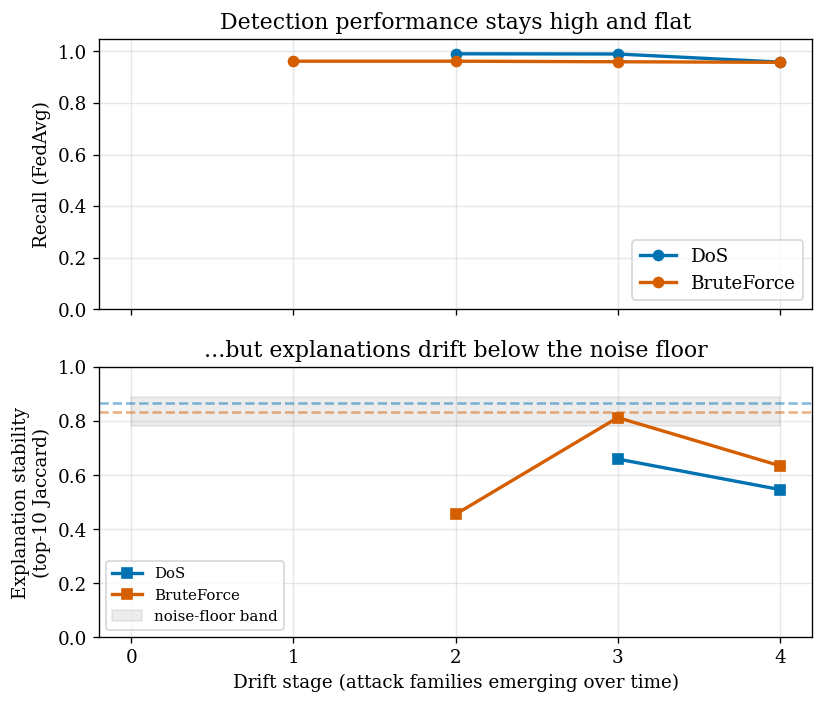

saved fig2


In [21]:
import json, numpy as np, matplotlib.pyplot as plt, os
PROJECT='/content/drive/MyDrive/fedxai-ids'; os.makedirs(f'{PROJECT}/figs',exist_ok=True)
plt.rcParams.update({'font.family':'serif','font.size':11,'axes.grid':True,'grid.alpha':0.3,'figure.dpi':120})

hist={(h['method'],h['stage']):h for h in json.load(open(f'{PROJECT}/train_history6.json'))}
floor=json.load(open(f'{PROJECT}/noise_floor.json'))
tci=json.load(open(f'{PROJECT}/temporal_ci.json'))
meta=json.load(open(f'{PROJECT}/meta6.json'))
import pandas as pd
df=pd.read_parquet(f'{PROJECT}/cicids2017_model6.parquet'); tr=df[df.split=='train']
STAGES=sorted(df['Stage'].unique()); fam2id=meta['fam2id']
CLS=['DoS','BruteForce']; emerge={c:int(tr[tr.y_family==fam2id[c]]['Stage'].min()) for c in CLS}

# reconstruct per-stage jaccard vs FIRST stage (consecutive chained) for the plot
# use train_history recall (top) + we approximate stage-wise stability from consecutive metrics file
tempm=json.load(open(f'{PROJECT}/explanation_metrics.json'))['temporal']

fig,(ax1,ax2)=plt.subplots(2,1,figsize=(7,6),sharex=True)
colors={'DoS':'#0072B2','BruteForce':'#D55E00'}
for c in CLS:
    rec=[hist[('fedavg',s)]['recall'][c] if s>=emerge[c] else np.nan for s in STAGES]
    ax1.plot(STAGES,rec,'o-',color=colors[c],label=c,lw=2)
ax1.set_ylabel('Recall (FedAvg)'); ax1.set_ylim(0,1.05); ax1.legend(loc='lower right')
ax1.set_title('Detection performance stays high and flat')

for c in CLS:
    e=emerge[c]; xs=[s for s in STAGES if s>e]
    ys=[tempm.get(f'fedavg|{c}|{a}->{b}',{}).get('jaccard',np.nan)
        for a,b in zip([s for s in STAGES if s>=e][:-1],[s for s in STAGES if s>e])]
    ax2.plot(xs,ys,'s-',color=colors[c],label=c,lw=2)
    fl=floor[c]['jaccard']; ax2.axhline(fl,ls='--',color=colors[c],alpha=0.5)
ax2.fill_between(STAGES,0.78,0.89,color='gray',alpha=0.15,label='noise-floor band')
ax2.set_ylabel('Explanation stability\n(top-10 Jaccard)'); ax2.set_xlabel('Drift stage (attack families emerging over time)')
ax2.set_ylim(0,1.0); ax2.set_xticks(STAGES); ax2.legend(loc='lower left',fontsize=9)
ax2.set_title('...but explanations drift below the noise floor')
plt.tight_layout(); plt.savefig(f'{PROJECT}/figs/fig2_accuracy_vs_explanation.png',bbox_inches='tight',dpi=300)
plt.show(); print("saved fig2")

# Fig 3: drift-magnitude dose-response

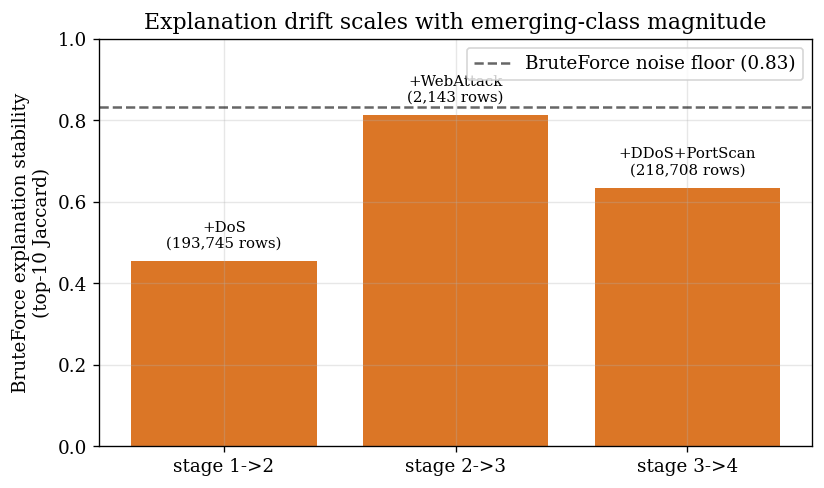

saved fig3


In [22]:
import json, numpy as np, matplotlib.pyplot as plt, pandas as pd
PROJECT='/content/drive/MyDrive/fedxai-ids'
plt.rcParams.update({'font.family':'serif','font.size':11})
tempm=json.load(open(f'{PROJECT}/explanation_metrics.json'))['temporal']
floor=json.load(open(f'{PROJECT}/noise_floor.json'))
df=pd.read_parquet(f'{PROJECT}/cicids2017_model6.parquet'); tr=df[df.split=='train']

# emerging class size per transition (what NEW family appears going a->b)
emerge_size={1:('BruteForce',9150),2:('DoS',193745),3:('WebAttack',2143),4:('DDoS+PortScan',218708)}
trans=['1->2','2->3','3->4']; newcls=[emerge_size[int(t.split('->')[1])] for t in trans]
bf=[tempm.get(f'fedavg|BruteForce|{t}',{}).get('jaccard',np.nan) for t in trans]
fl=floor['BruteForce']['jaccard']

fig,ax=plt.subplots(figsize=(7,4.2))
x=np.arange(len(trans))
bars=ax.bar(x,bf,color=['#D55E00' if v<fl else '#009E73' for v in bf],alpha=0.85)
ax.axhline(fl,ls='--',color='k',alpha=0.6,label=f'BruteForce noise floor ({fl:.2f})')
for i,(name,size) in enumerate(newcls):
    ax.annotate(f'+{name}\n({size:,} rows)',(x[i],bf[i]),textcoords='offset points',
                xytext=(0,8),ha='center',fontsize=9)
ax.set_xticks(x); ax.set_xticklabels([f'stage {t}' for t in trans])
ax.set_ylabel('BruteForce explanation stability\n(top-10 Jaccard)')
ax.set_ylim(0,1.0); ax.set_title('Explanation drift scales with emerging-class magnitude')
ax.legend(); plt.tight_layout()
plt.savefig(f'{PROJECT}/figs/fig3_dose_response.png',bbox_inches='tight',dpi=300); plt.show(); print("saved fig3")

# Fig 5: temporal vs cross-client dissociation

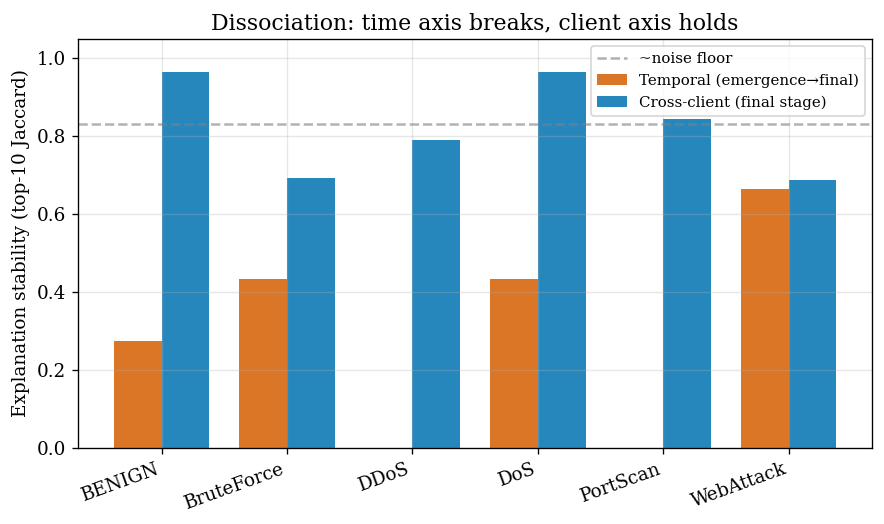

saved fig5


In [23]:
import json, numpy as np, matplotlib.pyplot as plt
PROJECT='/content/drive/MyDrive/fedxai-ids'
plt.rcParams.update({'font.family':'serif','font.size':11})
tci=json.load(open(f'{PROJECT}/temporal_ci.json'))
cc=json.load(open(f'{PROJECT}/cross_client.json'))
classes=['BENIGN','BruteForce','DDoS','DoS','PortScan','WebAttack']

temporal=[tci.get(f'fedavg|{c}',{}).get('mean',np.nan) for c in classes]
crosscl =[cc.get(c,{}).get('pair_jaccard',np.nan) for c in classes]

fig,ax=plt.subplots(figsize=(7.5,4.5))
x=np.arange(len(classes)); w=0.38
ax.bar(x-w/2,temporal,w,label='Temporal (emergence→final)',color='#D55E00',alpha=0.85)
ax.bar(x+w/2,crosscl ,w,label='Cross-client (final stage)',color='#0072B2',alpha=0.85)
ax.axhline(0.83,ls='--',color='gray',alpha=0.6,label='~noise floor')
ax.set_xticks(x); ax.set_xticklabels(classes,rotation=20,ha='right')
ax.set_ylabel('Explanation stability (top-10 Jaccard)'); ax.set_ylim(0,1.05)
ax.set_title('Dissociation: time axis breaks, client axis holds')
ax.legend(fontsize=9); plt.tight_layout()
plt.savefig(f'{PROJECT}/figs/fig5_dissociation.png',bbox_inches='tight',dpi=300); plt.show(); print("saved fig5")

# Fig 6: DoS top-feature reshuffling heatmap

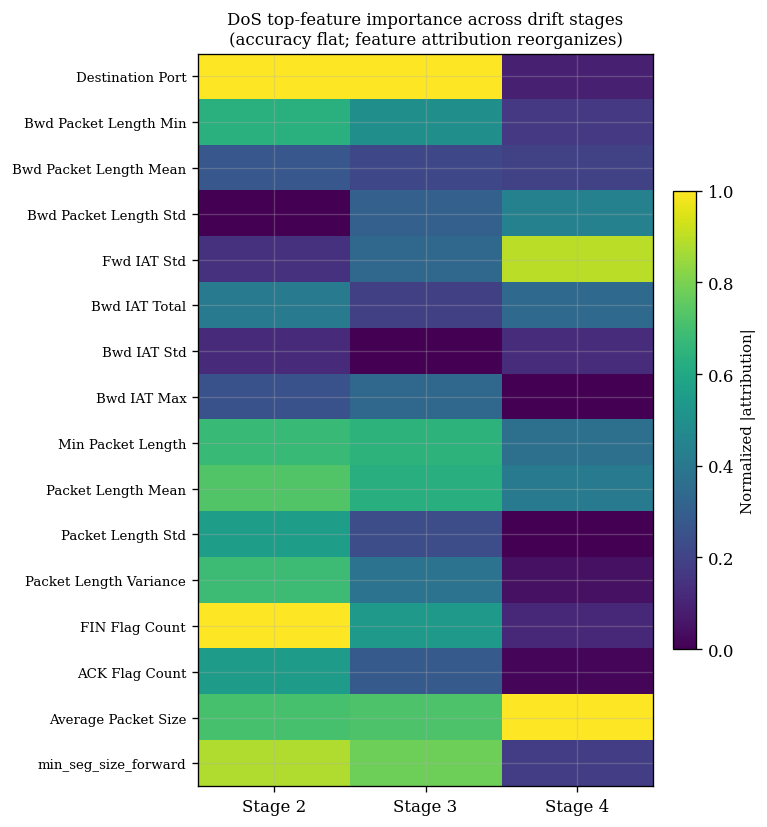

saved fig6


In [24]:
import json, numpy as np, matplotlib.pyplot as plt
PROJECT='/content/drive/MyDrive/fedxai-ids'
plt.rcParams.update({'font.family':'serif','font.size':10})
h=json.load(open(f'{PROJECT}/heatmap_dos.json'))
mat=np.array(h['matrix']); feats=h['feature_names']; stages=h['stages']

fig,ax=plt.subplots(figsize=(6.5,7))
im=ax.imshow(mat,aspect='auto',cmap='viridis')
ax.set_xticks(range(len(stages))); ax.set_xticklabels([f'Stage {s}' for s in stages])
ax.set_yticks(range(len(feats))); ax.set_yticklabels(feats,fontsize=8)
ax.set_title(f"{h['target']} top-feature importance across drift stages\n(accuracy flat; feature attribution reorganizes)",fontsize=10)
cbar=plt.colorbar(im,ax=ax,fraction=0.046,pad=0.04); cbar.set_label('Normalized |attribution|',fontsize=9)
plt.tight_layout(); plt.savefig(f'{PROJECT}/figs/fig6_dos_heatmap.png',bbox_inches='tight',dpi=300); plt.show(); print("saved fig6")

# Fig 4: FedAvg vs FedProx stabilization

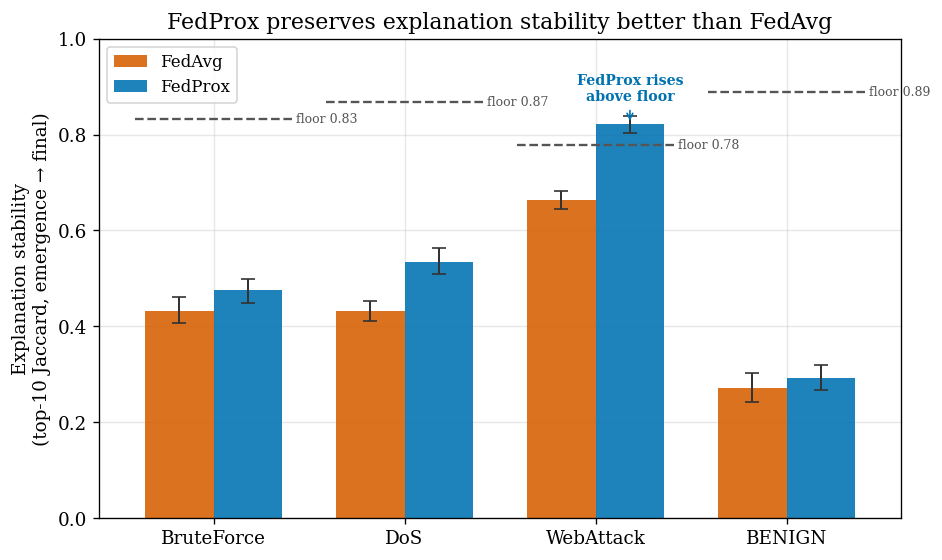

saved fig4 | values: {'BruteForce': (0.432, 0.475), 'DoS': (0.432, 0.535), 'WebAttack': (0.664, 0.822), 'BENIGN': (0.273, 0.293)}


In [26]:
import json, numpy as np, matplotlib.pyplot as plt, os
PROJECT='/content/drive/MyDrive/fedxai-ids'; os.makedirs(f'{PROJECT}/figs',exist_ok=True)
plt.rcParams.update({'font.family':'serif','font.size':11,'figure.dpi':120})

tci=json.load(open(f'{PROJECT}/temporal_ci.json'))
floor=json.load(open(f'{PROJECT}/noise_floor.json'))
classes=['BruteForce','DoS','WebAttack','BENIGN']

def get(method,c):
    d=tci[f'{method}|{c}']
    return d['mean'], d['mean']-d['ci_low'], d['ci_high']-d['mean']

avg=[get('fedavg',c) for c in classes]; prox=[get('fedprox',c) for c in classes]
avg_m=[a[0] for a in avg]; avg_e=[[a[1] for a in avg],[a[2] for a in avg]]
prox_m=[p[0] for p in prox]; prox_e=[[p[1] for p in prox],[p[2] for p in prox]]
floors=[floor[c]['jaccard'] for c in classes]

fig,ax=plt.subplots(figsize=(8,4.8))
ax.grid(True, axis='y', alpha=0.3)          # y-only grid, per-axes
ax.set_axisbelow(True)
x=np.arange(len(classes)); w=0.36
ax.bar(x-w/2,avg_m,w,yerr=avg_e,capsize=4,label='FedAvg',color='#D55E00',alpha=0.88,
       error_kw=dict(ecolor='#333333',lw=1.2))
ax.bar(x+w/2,prox_m,w,yerr=prox_e,capsize=4,label='FedProx',color='#0072B2',alpha=0.88,
       error_kw=dict(ecolor='#333333',lw=1.2))

for i,fl in enumerate(floors):
    ax.plot([x[i]-w-0.05, x[i]+w+0.05],[fl,fl],ls='--',color='#555555',lw=1.4)
    ax.annotate(f'floor {fl:.2f}',(x[i]+w+0.07,fl),fontsize=7.5,va='center',color='#555555')

wi=classes.index('WebAttack')
ax.annotate('FedProx rises\nabove floor',(x[wi]+w/2,prox_m[wi]),textcoords='offset points',
            xytext=(0,14),ha='center',fontsize=8.5,color='#0072B2',fontweight='bold',
            arrowprops=dict(arrowstyle='->',color='#0072B2'))

ax.set_xticks(x); ax.set_xticklabels(classes)
ax.set_ylabel('Explanation stability\n(top-10 Jaccard, emergence → final)')
ax.set_ylim(0,1.0)
ax.set_title('FedProx preserves explanation stability better than FedAvg')
ax.legend(loc='upper left',fontsize=10)
plt.tight_layout()
plt.savefig(f'{PROJECT}/figs/fig4_fedavg_vs_fedprox.png',bbox_inches='tight',dpi=300)
plt.show()
print("saved fig4 | values:", {c:(round(a,3),round(p,3)) for c,a,p in zip(classes,avg_m,prox_m)})